# Structural Damage Classification: Logistic Regression, SVM (OvA vs OvO), dan Neural Network

## 1. Project Overview

Notebook ini membangun dan membandingkan model klasifikasi multikelas untuk memprediksi tingkat kerusakan bangunan (`damage_grade`) pada kompetisi Kaggle **Structural Damage Classification**.

**Sumber data:** dataset asli kompetisi, dibaca dari `/kaggle/input/` (tambahkan melalui **Add Input** di Kaggle Notebook).

**Model yang dibandingkan:**

1. **Logistic Regression** multikelas (softmax/multinomial) dengan tuning `C`, `solver`, dan `class_weight`.
2. **Support Vector Machine (SVC)** yang dibungkus secara eksplisit dengan `OneVsRestClassifier` (**One-vs-All**) dan `OneVsOneClassifier` (**One-vs-One**).
3. **Neural Network (MLP)** TensorFlow/Keras dengan output softmax. Data bersifat tabular, sehingga CNN tidak digunakan.

**Metrik utama:** Macro F1, karena kelima kelas kerusakan dianggap sama penting dan distribusi kelas tidak seimbang. Accuracy, Weighted F1, precision, recall, confusion matrix, log loss, dan waktu komputasi digunakan sebagai informasi pendukung.

**Alur kerja dan pencegahan data leakage:**

- Data berlabel dibagi menjadi **train (80%)** dan **validation (20%)** secara stratified dengan `random_state=123`.
- Seluruh preprocessing berada di dalam `Pipeline`/`ColumnTransformer` dan hanya di-fit pada data training (atau pada fold training saat cross-validation).
- Tuning hyperparameter hanya memakai data training (Stratified K-Fold, atau validation internal yang diambil dari data training untuk Neural Network).
- Data validation hanya dipakai untuk evaluasi akhir dan satu kali pemilihan model final.
- Data test kompetisi tidak memiliki label, sehingga hanya dipakai untuk membuat `submission.csv`.

**Struktur dataset aktual (hasil pemeriksaan file kompetisi):**

- `train.csv` berisi `building_id`, 15 kolom fitur, dan target `damage_grade`. `test.csv` berisi kolom yang sama tanpa target.
- Label target berupa teks `"Grade 1"` sampai `"Grade 5"`. Format ini juga dipakai oleh `sample_submission.csv`, sehingga prediksi akhir **dikembalikan ke label teks asli** sebelum disimpan.
- `metadata.csv` kompetisi mendeskripsikan 11 kolom biner `has_superstructure_*`, tetapi file train/test menyimpan informasi tersebut dalam **satu kolom kategorikal `superstructure`** yang nilainya adalah nama flag. Notebook tidak mengasumsikan salah satu bentuk: kolom ditentukan dari file yang benar-benar dibaca (bagian 3).

> **Catatan penting:** semua angka, tabel, dan kesimpulan pada notebook ini dihasilkan oleh sel kode saat notebook dijalankan. Tidak ada angka hasil yang ditulis secara manual di Markdown.

## 2. Environment Setup and Configuration

### 2.1. Pengaturan Kaggle Notebook

Atur melalui panel **Settings** (sisi kanan editor Kaggle). Nama dan ketersediaan opsi dapat berbeda antarakun atau sesi, misalnya kuota GPU mingguan dan verifikasi nomor telepon untuk GPU/Internet.

| Pengaturan | Rekomendasi | Alasan |
|---|---|---|
| **Accelerator** | `None` (CPU) sudah cukup. `GPU` opsional bila tersedia. | Logistic Regression dan SVM di scikit-learn hanya berjalan di CPU. GPU hanya mempercepat Neural Network, dan untuk MLP kecil pada data tabular manfaatnya terbatas. Notebook tetap berjalan normal tanpa GPU. |
| **Internet** | `Off` | Dataset dibaca dari Kaggle Input dan semua library sudah tersedia di image Kaggle. |
| **Persistence** | Tidak wajib | Semua output (tabel hasil, gambar, `submission.csv`) disimpan ulang di `/kaggle/working/` setiap kali notebook dijalankan. |
| **Input** | Tambahkan data kompetisi *Structural Damage Classification* melalui **Add Input** | Notebook mencari file CSV secara otomatis di `/kaggle/input/`. |
| **Output** | `/kaggle/working/` | Output yang tersimpan di sini dapat diunduh dan `submission.csv` dapat dikirim ke kompetisi. |

Untuk membuat submission resmi, jalankan notebook dengan **Save Version → Save & Run All (Commit)**, lalu kirim `submission.csv` dari tab **Output**.

### 2.1b. Menjalankan Secara Lokal (opsional)

Kaggle tetap menjadi lingkungan utama. Jika `/kaggle/input` tidak ditemukan, notebook otomatis beralih ke mode lokal dengan struktur berikut (root proyek adalah folder induk dari `notebooks/`):

```text
structural-damage-classification/
├── data/
│   └── raw/
│       ├── train.csv
│       ├── test.csv
│       ├── sample_submission.csv   (opsional, untuk validasi format)
│       └── metadata.csv            (opsional, kamus data)
├── notebooks/
│   └── structural_damage_classification_v2.ipynb
├── outputs/        (dibuat otomatis: grafik dan tabel hasil)
└── submission/     (dibuat otomatis: submission.csv)
```

File tetap dikenali berdasarkan **isi kolomnya**, bukan namanya. Library yang dibutuhkan: `numpy`, `pandas`, `scipy`, `scikit-learn`, `matplotlib`, `seaborn`, dan `tensorflow`.

### 2.2. Import Library

Semua library di bawah ini sudah tersedia di image Python Kaggle, sehingga tidak ada instalasi tambahan dan tidak ada `pip install --upgrade`. Jika TensorFlow tidak tersedia, sel ini akan memberi pesan yang jelas.

In [1]:
import os
import sys
import re
import time
import json
import random
import platform
import itertools
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import scipy
from scipy import sparse

import sklearn
from sklearn.base import clone
from sklearn.model_selection import train_test_split, StratifiedKFold, GridSearchCV
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer, LabelEncoder
from sklearn.linear_model import LogisticRegression
from sklearn.svm import SVC, LinearSVC
from sklearn.multiclass import OneVsRestClassifier, OneVsOneClassifier
from sklearn.utils.class_weight import compute_class_weight
from sklearn.exceptions import ConvergenceWarning
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    log_loss,
    confusion_matrix,
    classification_report,
    precision_recall_fscore_support,
)

try:
    import tensorflow as tf
    from tensorflow import keras
    from tensorflow.keras import layers
except ImportError as exc:
    raise ImportError(
        "TensorFlow tidak ditemukan. Gunakan image Python default Kaggle "
        "(TensorFlow sudah terpasang) atau aktifkan Internet lalu jalankan "
        "`pip install tensorflow` pada satu cell setup."
    ) from exc

try:
    from IPython.display import display
except ImportError:
    display = print

pd.set_option("display.max_columns", 50)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid")

I0000 00:00:1791994966.713894    5698 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1791994966.758924    5698 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX512F AVX512_VNNI AVX512_BF16 AVX512_FP16 AVX_VNNI AMX_TILE AMX_INT8 AMX_BF16 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


I0000 00:00:1791994968.197061    5698 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


### 2.3. Pemeriksaan Environment

Sel ini menampilkan versi Python dan library utama, ketersediaan GPU, serta isi direktori input dan working. Pemeriksaan direktori dibuat aman, sehingga tidak error jika folder tidak ada.

In [2]:
print("Python       :", sys.version.split()[0])
print("Platform     :", platform.platform())
print("NumPy        :", np.__version__)
print("Pandas       :", pd.__version__)
print("SciPy        :", scipy.__version__)
print("Scikit-learn :", sklearn.__version__)
print("Matplotlib   :", matplotlib.__version__)
print("Seaborn      :", sns.__version__)
print("TensorFlow   :", tf.__version__)
print("Keras        :", keras.__version__)

gpus = tf.config.list_physical_devices("GPU")
print("\nGPU TensorFlow:", gpus if gpus else "tidak ada (Neural Network akan berjalan di CPU)")
for gpu in gpus:
    try:
        # Alokasi memori GPU secara bertahap agar tidak langsung memakan seluruh VRAM.
        tf.config.experimental.set_memory_growth(gpu, True)
    except RuntimeError as err:
        print("Tidak dapat mengatur memory growth:", err)

for folder in ["/kaggle/input", "/kaggle/working"]:
    print(f"\nIsi {folder}:")
    print(sorted(os.listdir(folder)) if os.path.isdir(folder) else "  (folder tidak ditemukan)")

try:
    import psutil
    print(f"\nRAM total: {psutil.virtual_memory().total / 1e9:.1f} GB | CPU logical cores: {os.cpu_count()}")
except ImportError:
    print(f"\nCPU logical cores: {os.cpu_count()}")

SKLEARN_VERSION = tuple(int(p) for p in re.findall(r"\d+", sklearn.__version__)[:2])
assert SKLEARN_VERSION >= (1, 1), "Notebook ini membutuhkan scikit-learn >= 1.1 (OneHotEncoder min_frequency)."

Python       : 3.13.16
Platform     : Linux-6.18.44-fc-v114-x86_64-with-glibc2.39
NumPy        : 2.5.3
Pandas       : 3.0.5
SciPy        : 1.18.1
Scikit-learn : 1.9.1
Matplotlib   : 3.11.2
Seaborn      : 0.13.2
TensorFlow   : 2.21.0
Keras        : 3.15.1

GPU TensorFlow: tidak ada (Neural Network akan berjalan di CPU)

Isi /kaggle/input:
['structural-damage-classification']

Isi /kaggle/working:
[]

RAM total: 16.9 GB | CPU logical cores: 4


### 2.4. Reproducibility

Random seed ditetapkan untuk Python, NumPy, dan TensorFlow, serta `random_state=SEED` dipakai pada setiap objek scikit-learn yang menyediakannya.

Seed membantu reproduksibilitas, tetapi **tidak menjamin hasil identik** di semua perangkat. Versi library yang berbeda, jumlah thread CPU, dan operasi GPU yang non-deterministik dapat menghasilkan sedikit perbedaan angka.

In [3]:
SEED = 123

os.environ["PYTHONHASHSEED"] = str(SEED)
random.seed(SEED)
np.random.seed(SEED)
tf.random.set_seed(SEED)

### 2.5. Konfigurasi Eksperimen dan Resource

Seluruh pengaturan yang memengaruhi waktu komputasi dikumpulkan di satu tempat agar mudah disesuaikan.

- **Logistic Regression** dituning pada subset stratified dari data training (`LR_TUNE_SIZE`) agar grid search 5-fold tetap ringan, lalu model terbaik dilatih ulang pada **seluruh** data training.
- **SVC (kernel SVM)** memiliki biaya pelatihan sekitar O(n²) hingga O(n³) terhadap jumlah sampel. Melatih SVC pada ratusan ribu baris tidak realistis di Kaggle, sehingga SVC dilatih pada subset stratified (`SVM_TRAIN_SIZE`). OvA dan OvO memakai **subset training yang sama** dan **seluruh data validation yang sama**. Sebagai pelengkap, `LinearSVC` (SVM linear yang skalabel) dilatih pada **seluruh** data training untuk melihat apakah kesimpulan berubah bila data penuh digunakan.
- **Neural Network** dilatih pada seluruh data training dengan EarlyStopping pada validation internal (diambil dari data training, bukan dari data validation).
- `FAST_DEV_RUN = True` hanya untuk uji cepat alur kode (debugging). Untuk eksperimen sebenarnya, biarkan `False`.

In [4]:
# ---- Kolom utama (sesuai deskripsi kompetisi; keberadaannya diverifikasi setelah data dibaca) ----
ID_COL = "building_id"
TARGET_COL = "damage_grade"

# ---- Path ----
# Kaggle (utama): data dibaca dari /kaggle/input, output ditulis ke /kaggle/working.
# Lokal (fallback): jika /kaggle/input tidak ada, root proyek = folder induk dari `notebooks/`
# (atau folder kerja saat ini), data dicari di <root>/data, output ditulis ke <root>/outputs
# dan <root>/submission. Tidak ada path absolute yang ditulis mati.
IS_KAGGLE = Path("/kaggle/input").is_dir()
if IS_KAGGLE:
    PROJECT_ROOT = None
    INPUT_ROOT = Path("/kaggle/input")
    WORKING_DIR = Path("/kaggle/working")
    OUTPUT_DIR = WORKING_DIR / "outputs"
    SUBMISSION_PATH = WORKING_DIR / "submission.csv"
else:
    PROJECT_ROOT = Path.cwd().parent if Path.cwd().name.lower() == "notebooks" else Path.cwd()
    INPUT_ROOT = PROJECT_ROOT / "data"
    WORKING_DIR = PROJECT_ROOT
    OUTPUT_DIR = PROJECT_ROOT / "outputs"
    SUBMISSION_PATH = PROJECT_ROOT / "submission" / "submission.csv"

TRAIN_PATH = None   # override manual jika perlu, mis. Path("../data/raw/train.csv")
TEST_PATH = None
SAMPLE_SUBMISSION_PATH = None

OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
SUBMISSION_PATH.parent.mkdir(parents=True, exist_ok=True)

# ---- Splitting ----
VALID_SIZE = 0.2

# ---- Preprocessing ----
AGE_SENTINEL = 999            # nilai umur bangunan yang diperlakukan sebagai kode "tidak diketahui" (lihat EDA)
OHE_MIN_FREQUENCY = 20        # kategori dengan frekuensi < nilai ini digabung menjadi kategori "infrequent"
                              # (relevan untuk ward_id yang memiliki ratusan kode wilayah)
HIGH_MISSING_THRESHOLD = 0.50 # kolom dengan missing > 50% dipertimbangkan untuk dihapus

# ---- Logistic Regression ----
LR_TUNE_SIZE = 60_000
LR_CV_FOLDS = 5
LR_MAX_ITER = 1000

# ---- SVM ----
SVM_TRAIN_SIZE = 20_000       # subset training untuk SVC OvA & OvO (sama untuk keduanya)
SVM_TUNE_SIZE = 6_000         # subset untuk GridSearchCV SVC
SVM_CV_FOLDS = 3
SVM_MAX_ITER = 200_000        # batas iterasi libsvm agar waktu tidak tak terkendali (warning tetap ditampilkan)
RUN_LINEAR_SVM_FULL = True    # LinearSVC OvA & OvO pada seluruh data training

# ---- Neural Network ----
NN_INTERNAL_VAL_SIZE = 0.1    # porsi data training untuk EarlyStopping & tuning NN
NN_TUNE_SIZE = 150_000
NN_TUNE_MAX_EPOCHS = 20
NN_MAX_EPOCHS = 60
NN_PATIENCE = 5

# ---- Mode uji cepat (hanya untuk debugging alur kode) ----
FAST_DEV_RUN = False
if FAST_DEV_RUN:
    LR_TUNE_SIZE, LR_CV_FOLDS = 3_000, 3
    SVM_TRAIN_SIZE, SVM_TUNE_SIZE = 1_500, 900
    NN_TUNE_SIZE, NN_TUNE_MAX_EPOCHS, NN_MAX_EPOCHS, NN_PATIENCE = 3_000, 3, 5, 2
    print("PERINGATAN: FAST_DEV_RUN aktif. Hasil hanya untuk uji alur kode, bukan untuk dilaporkan.")

print("Lingkungan       :", "Kaggle" if IS_KAGGLE else f"Lokal (root proyek: {PROJECT_ROOT})")
print("Folder data      :", INPUT_ROOT)
print("Output directory :", OUTPUT_DIR)
print("Submission path  :", SUBMISSION_PATH)

Lingkungan       : Kaggle
Folder data      : /kaggle/input
Output directory : /kaggle/working/outputs
Submission path  : /kaggle/working/submission.csv


## 3. Load Dataset

### 3.1. Menemukan Lokasi Dataset

Nama folder input dapat berbeda antarsesi (misalnya `/kaggle/input/<slug-kompetisi>/` atau `/kaggle/input/competitions/<slug-kompetisi>/`). Oleh karena itu, file tidak ditebak. Kode berikut:

1. menampilkan struktur folder di `/kaggle/input/`,
2. membaca header setiap file CSV,
3. menentukan peran file berdasarkan **isi kolomnya**:
   - **train**: memiliki `building_id` dan `damage_grade`, serta kolom fitur lainnya;
   - **test**: memiliki `building_id` tanpa `damage_grade`;
   - **sample submission**: hanya berisi `building_id` dan `damage_grade`.

In [5]:
def show_input_tree(root, max_files_per_dir=20):
    if not root.is_dir():
        print(f"{root} tidak ditemukan. Di Kaggle: tambahkan dataset melalui 'Add Input'. "
              "Di lokal: simpan train.csv dan test.csv di folder data/raw/ pada root proyek.")
        return
    for dirpath, dirnames, filenames in os.walk(root):
        dirnames.sort()
        depth = Path(dirpath).relative_to(root).parts
        indent = "    " * len(depth)
        print(f"{indent}{Path(dirpath).name}/")
        for name in sorted(filenames)[:max_files_per_dir]:
            size_mb = os.path.getsize(Path(dirpath) / name) / 1e6
            print(f"{indent}    {name}  ({size_mb:.1f} MB)")
        if len(filenames) > max_files_per_dir:
            print(f"{indent}    ... {len(filenames) - max_files_per_dir} file lainnya")


def detect_competition_files(root, id_col, target_col):
    roles = {"train": [], "test": [], "sample_submission": [], "metadata": []}
    for path in sorted(root.rglob("*.csv")):
        cols = list(pd.read_csv(path, nrows=0).columns)
        if id_col not in cols:
            # File kamus data (mis. metadata.csv) berisi daftar nama variabel, bukan baris bangunan.
            if {"Variable", "Description"}.issubset(cols):
                roles["metadata"].append(path)
            continue
        if target_col in cols and len(cols) == 2:
            roles["sample_submission"].append(path)
        elif target_col in cols:
            roles["train"].append(path)
        else:
            roles["test"].append(path)
    return roles


show_input_tree(INPUT_ROOT)

if TRAIN_PATH is None or TEST_PATH is None:
    detected = detect_competition_files(INPUT_ROOT, ID_COL, TARGET_COL) if INPUT_ROOT.is_dir() else {}
    print("\nHasil deteksi:", {k: [str(p) for p in v] for k, v in detected.items()})
    for role in ["train", "test"]:
        if len(detected.get(role, [])) != 1:
            raise FileNotFoundError(
                f"File '{role}' tidak dapat ditentukan secara unik ({detected.get(role)}). "
                f"Folder yang dipindai: {INPUT_ROOT}. Di Kaggle, tambahkan data kompetisi lewat 'Add Input'. "
                "Di lokal, simpan train.csv dan test.csv di <root proyek>/data/raw/, atau isi TRAIN_PATH/TEST_PATH secara manual."
            )
    TRAIN_PATH = TRAIN_PATH or detected["train"][0]
    TEST_PATH = TEST_PATH or detected["test"][0]
    if SAMPLE_SUBMISSION_PATH is None and len(detected.get("sample_submission", [])) == 1:
        SAMPLE_SUBMISSION_PATH = detected["sample_submission"][0]
    METADATA_PATH = detected["metadata"][0] if len(detected.get("metadata", [])) == 1 else None
else:
    METADATA_PATH = None

print("\nTRAIN_PATH             :", TRAIN_PATH)
print("TEST_PATH              :", TEST_PATH)
print("SAMPLE_SUBMISSION_PATH :", SAMPLE_SUBMISSION_PATH)
print("METADATA_PATH          :", METADATA_PATH)

input/
    structural-damage-classification/
        metadata.csv  (0.0 MB)
        sample_submission.csv  (5.0 MB)
        test.csv  (39.9 MB)
        train.csv  (97.4 MB)

Hasil deteksi: {'train': ['/kaggle/input/structural-damage-classification/train.csv'], 'test': ['/kaggle/input/structural-damage-classification/test.csv'], 'sample_submission': ['/kaggle/input/structural-damage-classification/sample_submission.csv'], 'metadata': ['/kaggle/input/structural-damage-classification/metadata.csv']}

TRAIN_PATH             : /kaggle/input/structural-damage-classification/train.csv
TEST_PATH              : /kaggle/input/structural-damage-classification/test.csv
SAMPLE_SUBMISSION_PATH : /kaggle/input/structural-damage-classification/sample_submission.csv
METADATA_PATH          : /kaggle/input/structural-damage-classification/metadata.csv


### 3.2. Membaca Data dan Pemeriksaan Awal

Dataset berbentuk CSV tabular, sehingga dibaca dengan Pandas. Di sini kita membedakan dua jenis data "test":

- **Data validation** (dibuat sendiri dari data training berlabel) untuk evaluasi lokal.
- **Data test resmi kompetisi** (`test_df`) yang tidak memiliki label dan hanya dipakai untuk submission.

In [6]:
train_raw = pd.read_csv(TRAIN_PATH)
test_df = pd.read_csv(TEST_PATH)
sample_submission = pd.read_csv(SAMPLE_SUBMISSION_PATH) if SAMPLE_SUBMISSION_PATH else None

for name, cols, required in [("train", train_raw.columns, [ID_COL, TARGET_COL]), ("test", test_df.columns, [ID_COL])]:
    missing = [c for c in required if c not in cols]
    if missing:
        raise KeyError(f"Kolom {missing} tidak ada di data {name}. Kolom tersedia: {list(cols)}")
assert TARGET_COL not in test_df.columns, "Data test resmi seharusnya tidak memiliki kolom target."

print("Ukuran train :", train_raw.shape)
print("Ukuran test  :", test_df.shape)
if sample_submission is not None:
    print("Ukuran sample submission:", sample_submission.shape)

only_train = sorted(set(train_raw.columns) - set(test_df.columns))
only_test = sorted(set(test_df.columns) - set(train_raw.columns))
print("\nKolom hanya di train:", only_train)
print("Kolom hanya di test :", only_test)
print("\nNama kolom train:", list(train_raw.columns))

Ukuran train : (533465, 17)
Ukuran test  : (228629, 16)
Ukuran sample submission: (228629, 2)

Kolom hanya di train: ['damage_grade']
Kolom hanya di test : []

Nama kolom train: ['building_id', 'district_id', 'vdcmun_id', 'ward_id', 'count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq', 'land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'damage_grade', 'superstructure']


**Metadata vs kolom aktual.** Kamus data kompetisi (`metadata.csv`, jika tersedia) dibandingkan dengan kolom yang benar-benar ada di file train. Perbedaan dicatat agar pemrosesan selanjutnya mengikuti **file aktual**, bukan deskripsi.

In [7]:
if METADATA_PATH is not None:
    metadata = pd.read_csv(METADATA_PATH)
    meta_vars = metadata["Variable"].astype(str).tolist()
    print("Variabel di metadata tetapi tidak ada di train:", [v for v in meta_vars if v not in train_raw.columns])
    print("Kolom di train tetapi tidak ada di metadata    :", [c for c in train_raw.columns if c not in meta_vars])
    if "superstructure" in train_raw.columns:
        values = sorted(train_raw["superstructure"].dropna().unique())
        flag_vars = [v for v in meta_vars if v.startswith("has_superstructure_")]
        print(f"\nKolom 'superstructure' memiliki {len(values)} nilai unik.")
        print("Semua nilai 'superstructure' adalah nama flag di metadata:", set(values).issubset(flag_vars))
        print("Contoh nilai:", values[:5])
else:
    print("metadata.csv tidak ditemukan; pemeriksaan kamus data dilewati.")

Variabel di metadata tetapi tidak ada di train: ['has_superstructure_adobe_mud', 'has_superstructure_mud_mortar_stone', 'has_superstructure_stone_flag', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick', 'has_superstructure_cement_mortar_brick', 'has_superstructure_timber', 'has_superstructure_bamboo', 'has_superstructure_rc_non_engineered', 'has_superstructure_rc_engineered', 'has_superstructure_other']
Kolom di train tetapi tidak ada di metadata    : ['superstructure']

Kolom 'superstructure' memiliki 11 nilai unik.
Semua nilai 'superstructure' adalah nama flag di metadata: True
Contoh nilai: ['has_superstructure_adobe_mud', 'has_superstructure_bamboo', 'has_superstructure_cement_mortar_brick', 'has_superstructure_cement_mortar_stone', 'has_superstructure_mud_mortar_brick']


**Interpretasi:** jika semua nilai `superstructure` merupakan nama flag `has_superstructure_*`, artinya setiap bangunan hanya dicatat dengan **satu** jenis material superstruktur dalam file ini. Kolom tersebut diperlakukan sebagai fitur kategorikal biasa dan di-one-hot-encode di pipeline, yang secara isi setara dengan flag biner pada metadata.

In [8]:
print("Tipe data:")
train_raw.info()
display(train_raw.head())

Tipe data:


<class 'pandas.DataFrame'>
RangeIndex: 533465 entries, 0 to 533464
Data columns (total 17 columns):
 #   Column                  Non-Null Count   Dtype
---  ------                  --------------   -----
 0   building_id             533465 non-null  int64
 1   district_id             533465 non-null  int64
 2   vdcmun_id               533465 non-null  int64
 3   ward_id                 533465 non-null  int64
 4   count_floors_pre_eq     533465 non-null  int64
 5   age_building            533465 non-null  int64
 6   plinth_area_sq_ft       533465 non-null  int64
 7   height_ft_pre_eq        533465 non-null  int64
 8   land_surface_condition  533465 non-null  str  
 9   foundation_type         533465 non-null  str  
 10  roof_type               533465 non-null  str  
 11  ground_floor_type       533465 non-null  str  
 12  other_floor_type        533465 non-null  str  
 13  position                533465 non-null  str  
 14  plan_configuration      533465 non-null  str  
 15  damage_grad

,building_id,district_id,vdcmun_id,ward_id,count_floors_pre_eq,age_building,plinth_area_sq_ft,height_ft_pre_eq,land_surface_condition,foundation_type,roof_type,ground_floor_type,other_floor_type,position,plan_configuration,damage_grade,superstructure
0,280803013271,28,2802,280202,3,42,504,21,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-2 side,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
1,311908002031,31,3104,310416,2,8,380,16,Flat,Cement-Stone/Brick,Bamboo/Timber-Heavy roof,Mud,Timber-Planck,Not attached,Rectangular,Grade 1,has_superstructure_cement_mortar_brick
2,310303000362,31,3111,311106,2,37,375,16,Moderate slope,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Not attached,Rectangular,Grade 5,has_superstructure_mud_mortar_stone
3,280806040201,28,2802,280206,2,70,319,15,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Mud,TImber/Bamboo-Mud,Attached-1 side,Rectangular,Grade 3,has_superstructure_adobe_mud
4,291301000371,29,2904,290404,1,25,495,6,Flat,Mud mortar-Stone/Brick,Bamboo/Timber-Light roof,Brick/Stone,Not applicable,Not attached,Rectangular,Grade 4,has_superstructure_mud_mortar_stone


In [9]:
print("Statistik deskriptif fitur numerik:")
display(train_raw.describe().T)

print("Statistik deskriptif fitur non-numerik:")
non_numeric_cols = [c for c in train_raw.columns if not pd.api.types.is_numeric_dtype(train_raw[c])]
display(train_raw[non_numeric_cols].describe().T)

Statistik deskriptif fitur numerik:


,count,mean,std,min,25%,50%,75%,max
building_id,533465.0,2.607139e+11,5.806563e+10,1.201010e+11,2.219060e+11,2.463010e+11,3.036070e+11,3.667090e+11
district_id,533465.0,2.576413e+01,5.812230e+00,1.200000e+01,2.200000e+01,2.400000e+01,3.000000e+01,3.600000e+01
vdcmun_id,533465.0,2.582312e+03,5.816406e+02,1.201000e+03,2.204000e+03,2.410000e+03,3.010000e+03,3.611000e+03
ward_id,533465.0,2.582367e+05,5.816413e+04,1.201010e+05,2.204010e+05,2.410040e+05,3.010050e+05,3.611080e+05
count_floors_pre_eq,533465.0,2.088000e+00,6.550006e-01,1.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00,9.000000e+00
age_building,533465.0,2.433732e+01,6.499906e+01,0.000000e+00,9.000000e+00,1.600000e+01,2.700000e+01,9.990000e+02
plinth_area_sq_ft,533465.0,4.065235e+02,2.266105e+02,7.000000e+01,2.800000e+02,3.580000e+02,4.700000e+02,5.000000e+03
height_ft_pre_eq,533465.0,1.604768e+01,5.490926e+00,6.000000e+00,1.200000e+01,1.600000e+01,1.800000e+01,9.900000e+01


Statistik deskriptif fitur non-numerik:


,count,unique,top,freq
land_surface_condition,533465,3,Flat,442089
foundation_type,533465,5,Mud mortar-Stone/Brick,440105
roof_type,533465,3,Bamboo/Timber-Light roof,352493
ground_floor_type,533465,5,Mud,432806
other_floor_type,533465,4,TImber/Bamboo-Mud,340906
position,533465,4,Not attached,423151
plan_configuration,533465,10,Rectangular,511999
damage_grade,533465,5,Grade 5,193036
superstructure,533465,11,has_superstructure_mud_mortar_stone,415327


### 3.3. Format Label Target

Label `damage_grade` diperiksa sebelum dipakai. Pada data kompetisi, label berupa teks (`"Grade 1"` … `"Grade 5"`). Untuk analisis internal, angka grade diekstrak menjadi bilangan bulat 1–5 karena:

- urutan kelas menjadi jelas (label bersifat **ordinal**), sehingga analisis kesalahan antarkelas bersebelahan dapat dihitung;
- `LabelEncoder` untuk Neural Network dapat dipakai secara konsisten.

Mapping dua arah (`LABEL_TO_INT` dan `INT_TO_LABEL`) disimpan. Prediksi akhir **dikembalikan ke label teks asli** sebelum `submission.csv` dibuat, sesuai format `sample_submission.csv`. Proses gagal secara eksplisit jika ada label tanpa angka atau mapping tidak satu-satu.

In [10]:
print("Nilai unik target (format asli):")
print(train_raw[TARGET_COL].value_counts().sort_index())


def parse_damage_grade(series):
    if pd.api.types.is_numeric_dtype(series):
        return series.astype(int)
    extracted = series.astype(str).str.extract(r"(\d+)", expand=False)
    if extracted.isna().any():
        bad = series[extracted.isna()].unique()[:10]
        raise ValueError(f"Label target tanpa angka grade ditemukan: {bad}")
    return extracted.astype(int)


label_mapping = (
    pd.DataFrame({"label_asli": train_raw[TARGET_COL], "label_angka": parse_damage_grade(train_raw[TARGET_COL])})
    .drop_duplicates()
    .sort_values("label_angka")
    .reset_index(drop=True)
)
display(label_mapping)
assert label_mapping["label_asli"].is_unique and label_mapping["label_angka"].is_unique, "Mapping label tidak satu-satu."

EXPECTED_CLASSES = [1, 2, 3, 4, 5]
CLASS_LABELS = sorted(label_mapping["label_angka"].tolist())
print("Kelas target:", CLASS_LABELS)
if CLASS_LABELS != EXPECTED_CLASSES:
    print("PERINGATAN: kelas pada data training berbeda dari kelas yang diharapkan kompetisi (1-5).")
N_CLASSES = len(CLASS_LABELS)

# Mapping dua arah untuk mengembalikan prediksi ke label asli kompetisi.
LABEL_TO_INT = dict(zip(label_mapping["label_asli"], label_mapping["label_angka"]))
INT_TO_LABEL = dict(zip(label_mapping["label_angka"], label_mapping["label_asli"]))
ORIGINAL_LABELS = [INT_TO_LABEL[c] for c in CLASS_LABELS]
print("Mapping internal -> label asli:", INT_TO_LABEL)

Nilai unik target (format asli):
damage_grade
Grade 1     55170
Grade 2     61080
Grade 3     95488
Grade 4    128691
Grade 5    193036
Name: count, dtype: int64


,label_asli,label_angka
0,Grade 1,1
1,Grade 2,2
2,Grade 3,3
3,Grade 4,4
4,Grade 5,5


Kelas target: [1, 2, 3, 4, 5]
Mapping internal -> label asli: {1: 'Grade 1', 2: 'Grade 2', 3: 'Grade 3', 4: 'Grade 4', 5: 'Grade 5'}


## 4. Quick EDA

### 4.1. Ringkasan Kolom serta Identifikasi Kolom ID, Konstan, dan Kosong

Tabel berikut merangkum tipe data, jumlah nilai unik, dan nilai kosong per kolom. Kolom konstan (hanya satu nilai) atau kolom yang seluruhnya kosong tidak membawa informasi untuk prediksi.

In [11]:
def column_summary(df):
    return pd.DataFrame({
        "dtype": df.dtypes.astype(str),
        "n_unique": df.nunique(dropna=True),
        "n_missing": df.isna().sum(),
        "pct_missing": (df.isna().mean() * 100).round(3),
        "contoh_nilai": [df[c].dropna().iloc[0] if df[c].notna().any() else None for c in df.columns],
    })


summary_train = column_summary(train_raw)
display(summary_train)

constant_cols = summary_train.index[summary_train["n_unique"] <= 1].tolist()
all_missing_cols = summary_train.index[summary_train["n_missing"] == len(train_raw)].tolist()
print("Kolom konstan          :", constant_cols)
print("Kolom seluruhnya kosong:", all_missing_cols)

,dtype,n_unique,n_missing,pct_missing,contoh_nilai
building_id,int64,533465,0,0.0,280803013271
district_id,int64,11,0,0.0,28
vdcmun_id,int64,110,0,0.0,2802
ward_id,int64,945,0,0.0,280202
count_floors_pre_eq,int64,9,0,0.0,3
age_building,int64,170,0,0.0,42
plinth_area_sq_ft,int64,1972,0,0.0,504
height_ft_pre_eq,int64,75,0,0.0,21
land_surface_condition,str,3,0,0.0,Flat
foundation_type,str,5,0,0.0,Mud mortar-Stone/Brick


Kolom konstan          : []
Kolom seluruhnya kosong: []


**Pemeriksaan kolom ID.** `building_id` diperiksa keunikannya dan ada-tidaknya irisan antara train dan test. Jika ID unik per baris, kolom ini hanya berfungsi sebagai identitas. Sel berikut juga memeriksa apakah awalan ID merepresentasikan kode wilayah yang sudah tersedia di kolom lain (misalnya `district_id`). Jika ya, informasi lokasi sudah tercakup oleh fitur wilayah, sehingga `building_id` tidak perlu dipakai sebagai fitur.

In [12]:
print(f"{ID_COL} unik di train :", train_raw[ID_COL].is_unique)
print(f"{ID_COL} unik di test  :", test_df[ID_COL].is_unique)
print(f"Irisan {ID_COL} train-test:", len(set(train_raw[ID_COL]) & set(test_df[ID_COL])))

if "district_id" in train_raw.columns and pd.api.types.is_integer_dtype(train_raw[ID_COL]):
    id_str = train_raw[ID_COL].astype(str)
    district_str = train_raw["district_id"].astype(str)
    prefix_match = (id_str.str[: 2] == district_str.str.zfill(2)).mean()
    print(f"Proporsi 2 digit awal {ID_COL} == district_id: {prefix_match:.4f}")

region_cols = [c for c in train_raw.columns if c.endswith("_id") and c != ID_COL]
print("\nKolom kode wilayah (berakhiran _id selain ID):", region_cols)
if region_cols:
    display(train_raw[region_cols].nunique().rename("n_unique").to_frame())

building_id unik di train : True
building_id unik di test  : True


Irisan building_id train-test: 0


Proporsi 2 digit awal building_id == district_id: 1.0000

Kolom kode wilayah (berakhiran _id selain ID): ['district_id', 'vdcmun_id', 'ward_id']


,n_unique
district_id,11
vdcmun_id,110
ward_id,945


### 4.2. Pemeriksaan Data Duplikat

Ada dua jenis duplikat yang perlu dibedakan:

1. **Duplikat baris penuh** (termasuk `building_id`): baris yang benar-benar tercatat dua kali. Baris seperti ini aman dihapus.
2. **Duplikat fitur** (semua fitur sama, tanpa `building_id`): bisa jadi bangunan berbeda yang kebetulan memiliki karakteristik tercatat yang sama. Baris ini **tidak** dihapus secara otomatis. Kita periksa juga apakah kelompok duplikat fitur memiliki label berbeda, karena hal tersebut menunjukkan noise yang tidak dapat dipisahkan oleh model mana pun.

In [13]:
n_rows = len(train_raw)
feature_like_cols = [c for c in train_raw.columns if c not in [ID_COL, TARGET_COL]]

full_dup = train_raw.duplicated().sum()
feature_dup_mask = train_raw.duplicated(subset=feature_like_cols, keep=False)
feature_dup_extra = train_raw.duplicated(subset=feature_like_cols).sum()

conflict_groups = (
    train_raw.loc[feature_dup_mask]
    .groupby(feature_like_cols, dropna=False)[TARGET_COL]
    .nunique()
)
n_conflict_groups = int((conflict_groups > 1).sum())
n_rows_in_conflict = int(
    train_raw.loc[feature_dup_mask]
    .groupby(feature_like_cols, dropna=False)[TARGET_COL]
    .transform("nunique")
    .gt(1)
    .sum()
)

dup_summary = pd.DataFrame({
    "jenis": [
        "Duplikat baris penuh (termasuk ID)",
        "Baris duplikat fitur (salinan tambahan)",
        "Baris dalam kelompok duplikat fitur",
        "Kelompok duplikat fitur dengan label berbeda",
        "Baris dalam kelompok berlabel berbeda",
    ],
    "jumlah": [full_dup, feature_dup_extra, int(feature_dup_mask.sum()), n_conflict_groups, n_rows_in_conflict],
})
dup_summary["persen_dari_train"] = (dup_summary["jumlah"] / n_rows * 100).round(3)
display(dup_summary)
print("Duplikat baris penuh di test:", test_df.duplicated().sum())

,jenis,jumlah,persen_dari_train
0,Duplikat baris penuh (termasuk ID),0,0.000
1,Baris duplikat fitur (salinan tambahan),34062,6.385
2,Baris dalam kelompok duplikat fitur,56682,10.625
3,Kelompok duplikat fitur dengan label berbeda,10695,2.005
4,Baris dalam kelompok berlabel berbeda,29104,5.456


Duplikat baris penuh di test: 0


**Keputusan:** hanya duplikat baris penuh yang dihapus (jika ada). Duplikat fitur dipertahankan karena `building_id` berbeda menunjukkan bangunan yang berbeda, dan menghapusnya akan mengubah distribusi kelas. Proporsi kelompok berlabel berbeda pada tabel di atas memberi gambaran batas atas performa: untuk baris-baris tersebut, model tidak mungkin memprediksi semuanya dengan benar.

### 4.3. Heatmap dan Tabel Missing Values

Heatmap memperlihatkan lokasi nilai kosong (`isna()`). Agar gambar tetap terbaca dan ringan, heatmap dibuat dari sampel acak baris. Tabel di bawahnya dihitung dari **seluruh** baris train dan test.

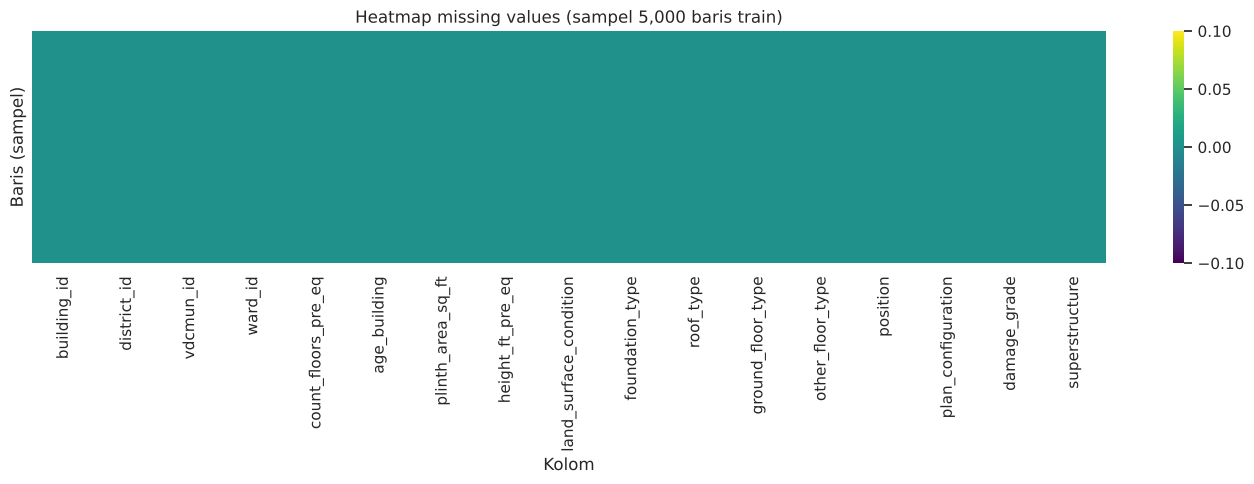

,kolom,n_missing_train,pct_missing_train,dtype,n_missing_test,pct_missing_test
0,building_id,0,0.0,int64,0.0,0.0
1,district_id,0,0.0,int64,0.0,0.0
2,vdcmun_id,0,0.0,int64,0.0,0.0
3,ward_id,0,0.0,int64,0.0,0.0
4,count_floors_pre_eq,0,0.0,int64,0.0,0.0
5,age_building,0,0.0,int64,0.0,0.0
6,plinth_area_sq_ft,0,0.0,int64,0.0,0.0
7,height_ft_pre_eq,0,0.0,int64,0.0,0.0
8,land_surface_condition,0,0.0,str,0.0,0.0
9,foundation_type,0,0.0,str,0.0,0.0


Total nilai kosong train: 0 | test: 0


In [14]:
sample_rows = train_raw.sample(n=min(5000, len(train_raw)), random_state=SEED)
fig, ax = plt.subplots(figsize=(14, 5))
sns.heatmap(sample_rows.isna(), cbar=True, yticklabels=False, cmap="viridis", ax=ax)
ax.set_title(f"Heatmap missing values (sampel {len(sample_rows):,} baris train)")
ax.set_xlabel("Kolom")
ax.set_ylabel("Baris (sampel)")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "missing_heatmap.png", dpi=120)
plt.show()

missing_table = pd.DataFrame({
    "kolom": train_raw.columns,
    "n_missing_train": train_raw.isna().sum().values,
    "pct_missing_train": (train_raw.isna().mean() * 100).round(3).values,
    "dtype": train_raw.dtypes.astype(str).values,
})
missing_table["n_missing_test"] = [test_df[c].isna().sum() if c in test_df else np.nan for c in train_raw.columns]
missing_table["pct_missing_test"] = [round(test_df[c].isna().mean() * 100, 3) if c in test_df else np.nan for c in train_raw.columns]
display(missing_table.sort_values("pct_missing_train", ascending=False).reset_index(drop=True))
print("Total nilai kosong train:", int(train_raw.isna().sum().sum()), "| test:", int(test_df.isna().sum().sum()))

**Interpretasi:** jika heatmap tampak seragam dan tabel menunjukkan nol nilai kosong, dataset tidak memiliki missing values eksplisit. Imputer tetap dipasang di pipeline sebagai pengaman bila data test resmi memiliki nilai kosong. Nilai yang secara implisit berarti "tidak diketahui" (misalnya kode khusus pada kolom umur) ditangani di bagian 4.5.

### 4.4. Menangani Kolom dengan Missing Values Tinggi

Ambang `HIGH_MISSING_THRESHOLD = 50%` dipakai sebagai batas pertimbangan. Pada kolom dengan lebih dari separuh nilai kosong, imputasi akan lebih banyak "mengarang" nilai daripada menggunakan data asli. Kolom di atas ambang tidak langsung dihapus, tetapi ditandai untuk ditinjau. Kolom di bawah ambang dipertahankan dan diimputasi di dalam pipeline.

In [15]:
high_missing_cols = missing_table.loc[
    missing_table["pct_missing_train"] > HIGH_MISSING_THRESHOLD * 100, "kolom"
].tolist()
high_missing_cols = [c for c in high_missing_cols if c not in [ID_COL, TARGET_COL]]

if high_missing_cols:
    print("Kolom dengan missing di atas ambang:", high_missing_cols)
    print("Kolom ini akan dihapus dari fitur karena mayoritas nilainya tidak tersedia.")
else:
    print(f"Tidak ada kolom dengan missing > {HIGH_MISSING_THRESHOLD:.0%}. Tidak ada kolom yang dihapus karena missing values.")

Tidak ada kolom dengan missing > 50%. Tidak ada kolom yang dihapus karena missing values.


### 4.5. Visualisasi Distribusi Data

#### Distribusi target dan ketidakseimbangan kelas

,jumlah,persen
damage_grade,,
1,55170,10.34
2,61080,11.45
3,95488,17.90
4,128691,24.12
5,193036,36.19


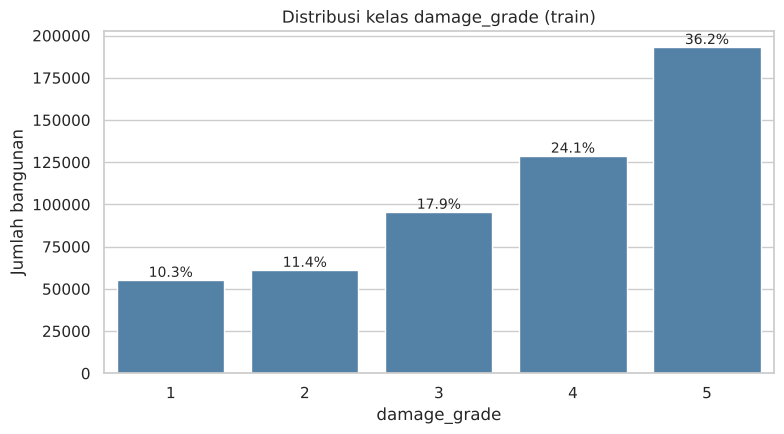

Kelas terbanyak: 5 (193,036) | kelas tersedikit: 1 (55,170) | rasio: 3.50


In [16]:
y_all_numeric = parse_damage_grade(train_raw[TARGET_COL])
class_counts = y_all_numeric.value_counts().sort_index()
class_pct = (class_counts / class_counts.sum() * 100).round(2)
display(pd.DataFrame({"jumlah": class_counts, "persen": class_pct}))

fig, ax = plt.subplots(figsize=(8, 4.5))
sns.countplot(x=y_all_numeric, order=CLASS_LABELS, color="steelblue", ax=ax)
for patch, pct in zip(ax.patches, class_pct.values):
    ax.annotate(f"{pct:.1f}%", (patch.get_x() + patch.get_width() / 2, patch.get_height()),
                ha="center", va="bottom", fontsize=10)
ax.set_title("Distribusi kelas damage_grade (train)")
ax.set_xlabel("damage_grade")
ax.set_ylabel("Jumlah bangunan")
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "target_distribution.png", dpi=120)
plt.show()

imbalance_ratio = class_counts.max() / class_counts.min()
print(f"Kelas terbanyak: {class_counts.idxmax()} ({class_counts.max():,}) | "
      f"kelas tersedikit: {class_counts.idxmin()} ({class_counts.min():,}) | rasio: {imbalance_ratio:.2f}")

**Interpretasi:** rasio kelas terbanyak terhadap kelas tersedikit menunjukkan tingkat ketidakseimbangan. Semakin besar rasionya, semakin mungkin Accuracy tampak baik hanya karena model sering menebak kelas mayoritas. Itulah alasan Macro F1 dipakai sebagai metrik utama dan `class_weight="balanced"` diuji saat tuning.

#### Distribusi fitur numerik

Fitur numerik (kuantitas fisik): ['count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq']


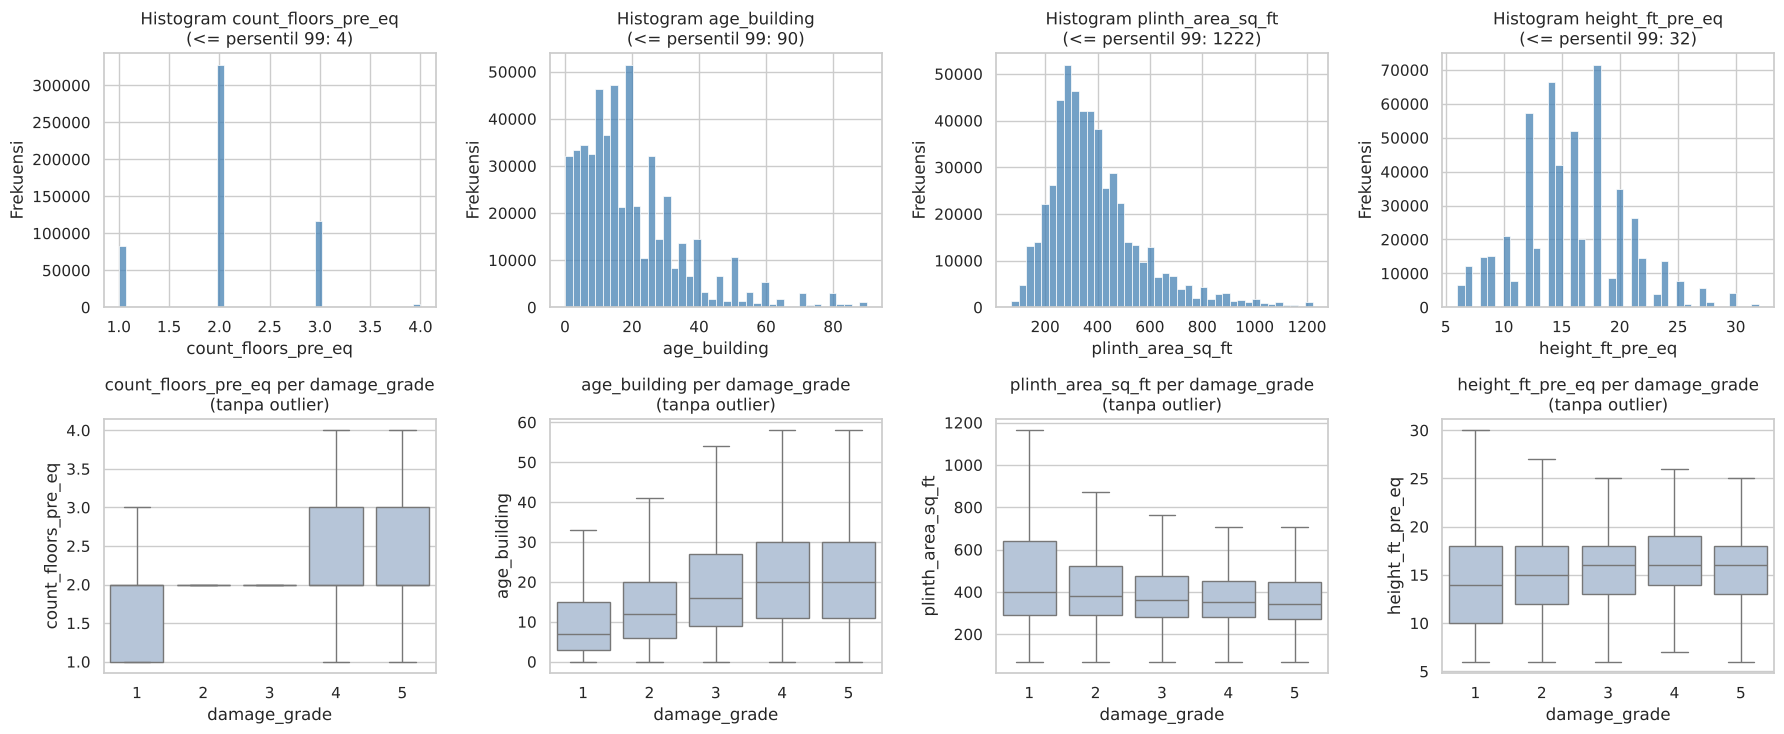

,0.500,0.900,0.990,0.999,1.000
count_floors_pre_eq,2.0,3.0,4.0,5.000,9.0
age_building,16.0,40.0,90.0,999.000,999.0
plinth_area_sq_ft,358.0,645.0,1222.0,2340.536,5000.0
height_ft_pre_eq,16.0,22.0,32.0,50.000,99.0


In [17]:
numeric_eda_cols = [
    c for c in train_raw.columns
    if c not in [ID_COL, TARGET_COL] and pd.api.types.is_numeric_dtype(train_raw[c]) and not c.endswith("_id")
]
print("Fitur numerik (kuantitas fisik):", numeric_eda_cols)

if numeric_eda_cols:
    n = len(numeric_eda_cols)
    fig, axes = plt.subplots(2, n, figsize=(4.5 * n, 7.5), squeeze=False)
    for i, col in enumerate(numeric_eda_cols):
        upper = train_raw[col].quantile(0.99)
        sns.histplot(train_raw.loc[train_raw[col] <= upper, col], bins=40, ax=axes[0, i], color="steelblue")
        axes[0, i].set_title(f"Histogram {col}\n(<= persentil 99: {upper:g})")
        axes[0, i].set_xlabel(col)
        axes[0, i].set_ylabel("Frekuensi")
        sns.boxplot(x=y_all_numeric, y=train_raw[col], order=CLASS_LABELS, ax=axes[1, i], showfliers=False, color="lightsteelblue")
        axes[1, i].set_title(f"{col} per damage_grade\n(tanpa outlier)")
        axes[1, i].set_xlabel("damage_grade")
        axes[1, i].set_ylabel(col)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "numeric_distribution.png", dpi=120)
    plt.show()

    display(train_raw[numeric_eda_cols].quantile([0.5, 0.9, 0.99, 0.999, 1.0]).T)

**Pemeriksaan nilai khusus pada umur bangunan.** Nilai umur yang tepat sama dengan `AGE_SENTINEL` (999) secara fisik tidak masuk akal dan umum dipakai sebagai kode "tidak diketahui". Jika jumlahnya jauh lebih banyak daripada nilai besar lain di sekitarnya, nilai tersebut diperlakukan sebagai missing di dalam pipeline (bukan dihapus), lalu diimputasi median dengan indikator missing.

In [18]:
if "age_building" in train_raw.columns:
    age = train_raw["age_building"]
    print(f"age_building == {AGE_SENTINEL}: {(age == AGE_SENTINEL).sum():,} baris ({(age == AGE_SENTINEL).mean():.2%})")
    print(f"age_building > 100 (selain {AGE_SENTINEL}): {((age > 100) & (age != AGE_SENTINEL)).sum():,} baris")
    print("10 nilai umur terbesar yang paling sering muncul:")
    display(age[age > 100].value_counts().head(10).rename("jumlah").to_frame())
    print("Proporsi damage_grade untuk age_building == sentinel vs lainnya (%):")
    display((pd.crosstab(age == AGE_SENTINEL, y_all_numeric, normalize="index") * 100).round(2))
else:
    print("Kolom age_building tidak ditemukan; penanganan sentinel umur dilewati.")

age_building == 999: 2,198 baris (0.41%)
age_building > 100 (selain 999): 997 baris
10 nilai umur terbesar yang paling sering muncul:


,jumlah
age_building,
999,2198
200,178
150,156
120,133
110,110
105,70
102,32
101,24
125,23


Proporsi damage_grade untuk age_building == sentinel vs lainnya (%):


damage_grade,1,2,3,4,5
age_building,,,,,
False,10.34,11.45,17.89,24.13,36.19
True,11.92,11.42,19.75,21.61,35.30


**Interpretasi:** histogram memperlihatkan bentuk distribusi (kemiringan dan nilai ekstrem), sedangkan boxplot per kelas menunjukkan apakah fitur numerik berbeda antartingkat kerusakan. Fitur yang median-nya bergeser antarkelas berpotensi informatif. Karena skala dan sebaran fitur berbeda jauh, standardisasi diperlukan untuk Logistic Regression, SVM, dan Neural Network.

#### Distribusi fitur kategorikal

Fitur kategorikal: ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'superstructure']
Kardinalitas tinggi (tidak di-plot sebagai countplot): []


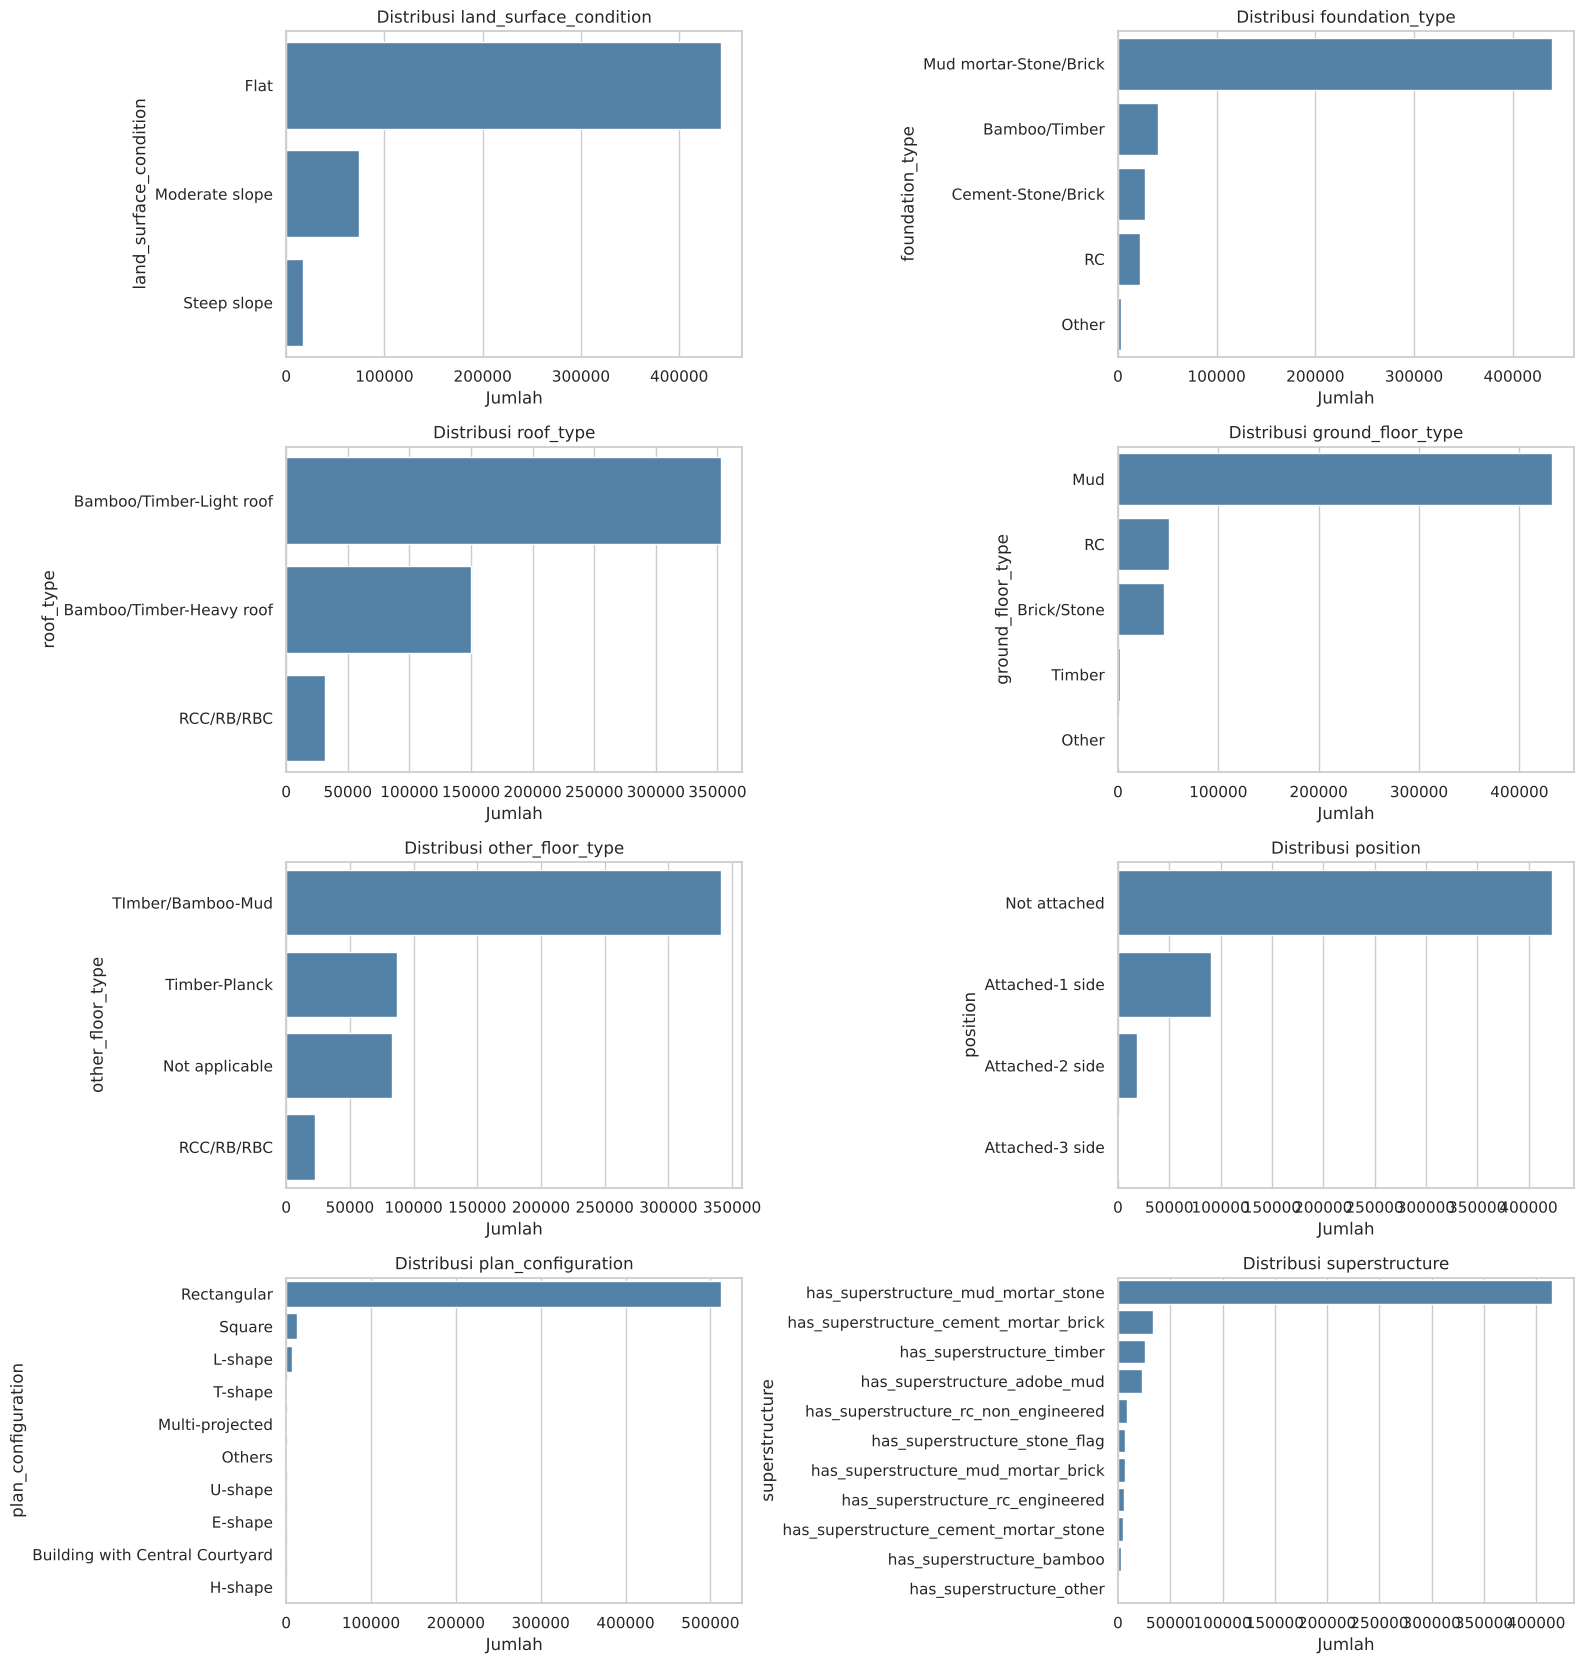

In [19]:
categorical_eda_cols = [
    c for c in train_raw.columns
    if c not in [ID_COL, TARGET_COL] and not pd.api.types.is_numeric_dtype(train_raw[c])
]
low_card_cols = [c for c in categorical_eda_cols if train_raw[c].nunique() <= 15]
high_card_cols = [c for c in categorical_eda_cols if c not in low_card_cols]
print("Fitur kategorikal:", categorical_eda_cols)
print("Kardinalitas tinggi (tidak di-plot sebagai countplot):", high_card_cols)

if low_card_cols:
    ncols = 2
    nrows = int(np.ceil(len(low_card_cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(16, 4.2 * nrows), squeeze=False)
    for ax, col in zip(axes.ravel(), low_card_cols):
        order = train_raw[col].value_counts().index
        sns.countplot(y=train_raw[col], order=order, ax=ax, color="steelblue")
        ax.set_title(f"Distribusi {col}")
        ax.set_xlabel("Jumlah")
        ax.set_ylabel(col)
    for ax in axes.ravel()[len(low_card_cols):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "categorical_distribution.png", dpi=120)
    plt.show()

for col in high_card_cols:
    print(f"\n{col}: {train_raw[col].nunique()} kategori, 10 terbanyak:")
    display(train_raw[col].value_counts().head(10).rename("jumlah").to_frame())

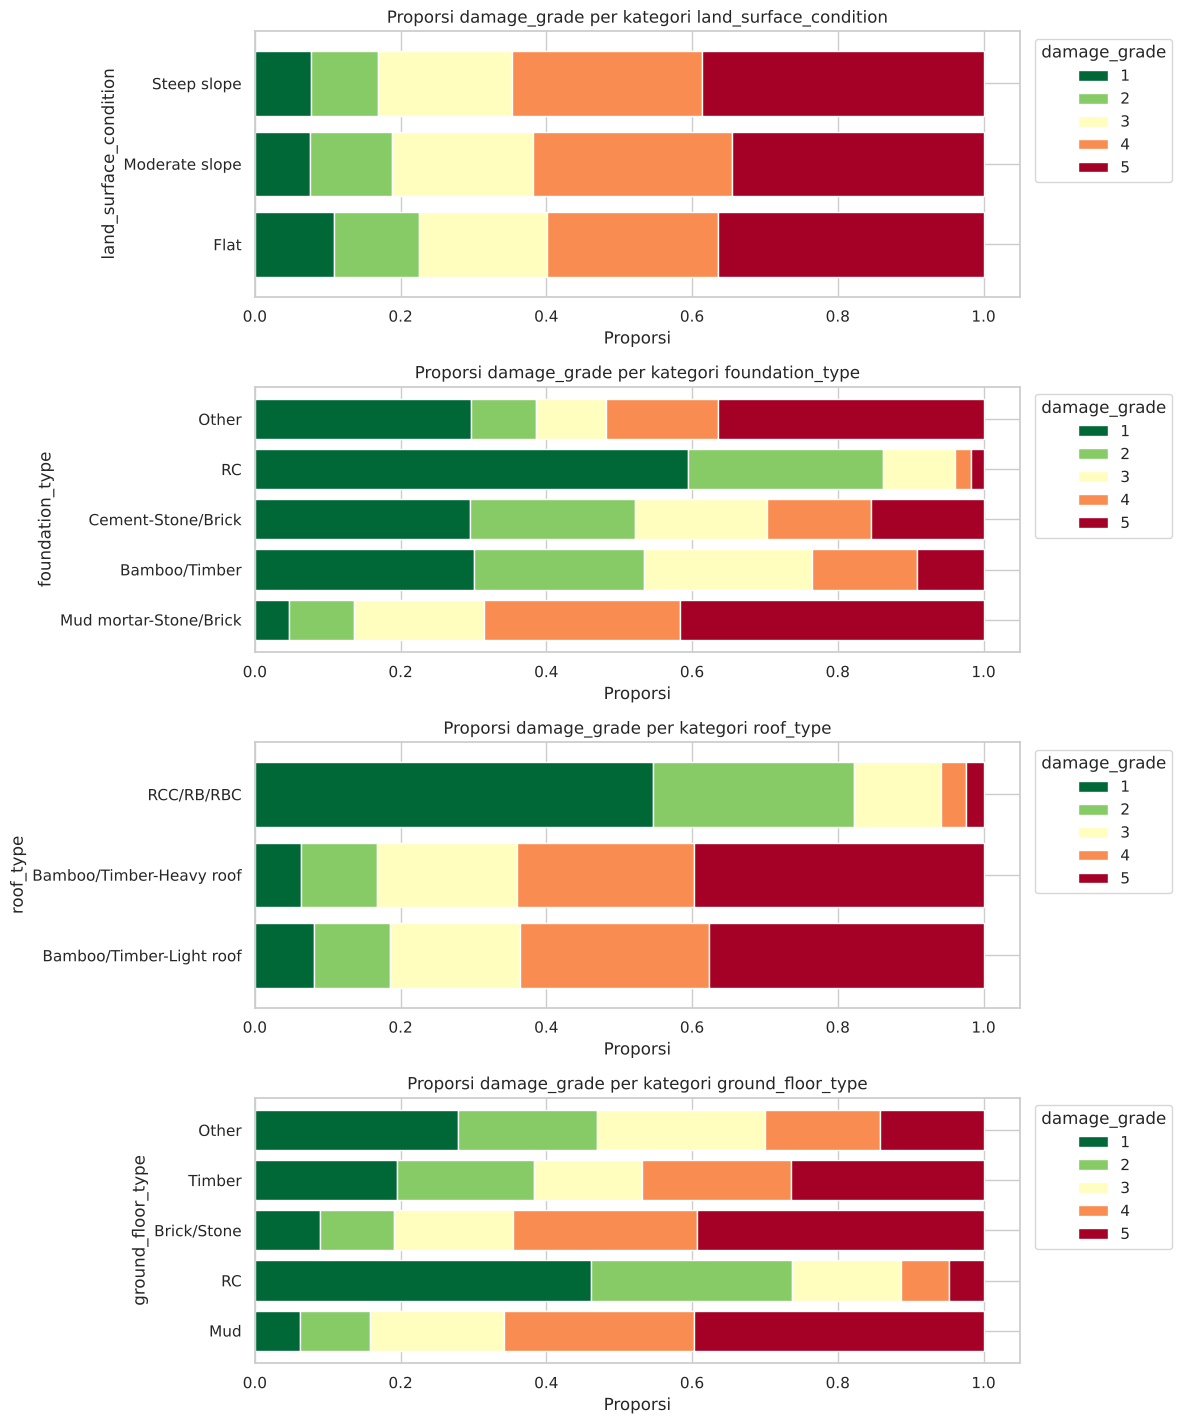

In [20]:
# Proporsi damage_grade per kategori untuk beberapa fitur kategorikal: melihat hubungan fitur dengan target.
plot_cols = [c for c in low_card_cols if train_raw[c].nunique() <= 12][:4]
if plot_cols:
    fig, axes = plt.subplots(len(plot_cols), 1, figsize=(12, 3.6 * len(plot_cols)), squeeze=False)
    for ax, col in zip(axes.ravel(), plot_cols):
        ct = pd.crosstab(train_raw[col], y_all_numeric, normalize="index")
        ct = ct.loc[train_raw[col].value_counts().index]
        ct.plot(kind="barh", stacked=True, ax=ax, colormap="RdYlGn_r", width=0.8)
        ax.set_title(f"Proporsi damage_grade per kategori {col}")
        ax.set_xlabel("Proporsi")
        ax.set_ylabel(col)
        ax.legend(title="damage_grade", bbox_to_anchor=(1.01, 1), loc="upper left")
    plt.tight_layout()
    plt.savefig(OUTPUT_DIR / "categorical_vs_target.png", dpi=120)
    plt.show()

**Interpretasi:** countplot menunjukkan kategori yang dominan dan kategori langka. Kategori langka digabung oleh `OneHotEncoder(min_frequency=...)` agar dimensi tidak membengkak dan model tidak mempelajari kategori yang hampir tidak pernah muncul. Grafik proporsi memperlihatkan apakah komposisi tingkat kerusakan berbeda antarkategori. Jika berbeda, fitur tersebut kemungkinan informatif.

Kolom kode wilayah (berakhiran `_id`, misalnya distrik, municipality, dan ward) bertipe angka, tetapi nilainya adalah **kode**, bukan besaran. Oleh karena itu, kolom ini diperlakukan sebagai kategorikal.

## 5. Data Cleaning

Keputusan cleaning berdasarkan EDA:

| Langkah | Keputusan | Alasan |
|---|---|---|
| Duplikat baris penuh | Dihapus (jika ada) | Pencatatan ganda tidak menambah informasi. |
| Duplikat fitur | Dipertahankan | Bangunan berbeda (`building_id` berbeda). Menghapusnya akan mengubah distribusi kelas. |
| Kolom konstan atau seluruhnya kosong | Dihapus dari fitur (jika ada) | Tidak membawa informasi. |
| Kolom dengan missing > ambang | Dihapus dari fitur (jika ada) | Mayoritas nilai tidak tersedia. |
| `building_id` | Disimpan untuk submission, **tidak** dipakai sebagai fitur | Identitas unik. Informasi lokasinya sudah tercakup oleh kolom wilayah. |
| `age_building == 999` | Diubah menjadi missing **di dalam pipeline** | Kode "tidak diketahui". Transformasi ini deterministik (tanpa fit), sehingga tidak menimbulkan leakage. |
| Label target | Dikonversi menjadi bilangan bulat 1–5 **hanya untuk pemodelan internal** | Urutan ordinal jelas. Prediksi dikembalikan ke label asli (`"Grade N"`) saat submission. Mapping diverifikasi di bagian 3.3. |
| `superstructure` | Dipertahankan sebagai fitur kategorikal | Satu kolom berisi nama material superstruktur (lihat bagian 3.2). |

In [21]:
train_df = train_raw.drop_duplicates().reset_index(drop=True)
print(f"Baris dihapus karena duplikat penuh: {len(train_raw) - len(train_df):,}")

train_df[TARGET_COL] = parse_damage_grade(train_df[TARGET_COL])

drop_feature_cols = sorted(set(constant_cols + all_missing_cols + high_missing_cols) - {ID_COL, TARGET_COL})
print("Kolom yang dikeluarkan dari fitur:", drop_feature_cols if drop_feature_cols else "(tidak ada)")
print("Ukuran train setelah cleaning:", train_df.shape)

Baris dihapus karena duplikat penuh: 0


Kolom yang dikeluarkan dari fitur: (tidak ada)
Ukuran train setelah cleaning: (533465, 17)


## 6. Feature and Target Separation

- `X` berisi semua kolom kecuali `building_id`, target, dan kolom yang dikeluarkan di bagian 5.
- `y` berisi label `damage_grade` dalam bentuk angka 1–5 (hasil mapping dari `"Grade N"`). Label ordinal ini dipertahankan untuk interpretasi. Encoding ke 0–4 hanya dilakukan untuk Neural Network, dengan `LabelEncoder` yang dapat di-inverse.
- **Fitur numerik**: kolom numerik yang merupakan besaran fisik.
- **Fitur kategorikal**: kolom teks ditambah kolom kode wilayah (`*_id` selain `building_id`).

In [22]:
feature_cols = [c for c in train_df.columns if c not in [ID_COL, TARGET_COL] + drop_feature_cols]

missing_in_test = [c for c in feature_cols if c not in test_df.columns]
if missing_in_test:
    raise KeyError(f"Fitur berikut tidak ada di data test resmi: {missing_in_test}")

X = train_df[feature_cols].copy()
y = train_df[TARGET_COL].copy()

region_code_features = [c for c in feature_cols if c.endswith("_id")]
numerical_features = [c for c in feature_cols if pd.api.types.is_numeric_dtype(X[c]) and c not in region_code_features]
categorical_features = [c for c in feature_cols if not pd.api.types.is_numeric_dtype(X[c])] + region_code_features

assert ID_COL not in numerical_features + categorical_features
assert TARGET_COL not in numerical_features + categorical_features
assert sorted(numerical_features + categorical_features) == sorted(feature_cols)

print("numerical_features  :", numerical_features)
print("categorical_features:", categorical_features)
print("X:", X.shape, "| y:", y.shape)

numerical_features  : ['count_floors_pre_eq', 'age_building', 'plinth_area_sq_ft', 'height_ft_pre_eq']
categorical_features: ['land_surface_condition', 'foundation_type', 'roof_type', 'ground_floor_type', 'other_floor_type', 'position', 'plan_configuration', 'superstructure', 'district_id', 'vdcmun_id', 'ward_id']
X: (533465, 15) | y: (533465,)


## 7. Train-Validation Splitting

Data berlabel dibagi 80:20 secara stratified:

- `test_size=0.2`: 20% data menjadi validation (holdout) untuk evaluasi akhir.
- `stratify=y`: proporsi setiap kelas di train dan validation dijaga tetap sama dengan data asli. Hal ini penting karena kelas tidak seimbang.
- `random_state=123`: pembagian yang sama setiap kali notebook dijalankan.

**Risiko leakage karena kelompok:** bangunan dalam satu ward/municipality cenderung berkorelasi (karakteristik gempa lokal serupa). Split acak menempatkan bangunan dari wilayah yang sama di train dan validation. Ini sesuai dengan skenario kompetisi, **jika** data test resmi juga berasal dari wilayah yang muncul di train. Sel berikut memeriksa hal tersebut. Jika banyak wilayah test tidak muncul di train, split berbasis kelompok (`StratifiedGroupKFold`) lebih tepat.

In [23]:
for col in region_code_features:
    coverage = test_df[col].isin(set(train_df[col])).mean()
    print(f"Proporsi baris test dengan {col} yang juga ada di train: {coverage:.4f}")

X_train, X_valid, y_train, y_valid = train_test_split(
    X, y, test_size=VALID_SIZE, stratify=y, random_state=SEED
)
print("\nX_train:", X_train.shape, "| X_valid:", X_valid.shape)
print("y_train:", y_train.shape, "| y_valid:", y_valid.shape)

split_dist = pd.DataFrame({
    "train_n": y_train.value_counts().sort_index(),
    "train_%": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    "valid_n": y_valid.value_counts().sort_index(),
    "valid_%": (y_valid.value_counts(normalize=True).sort_index() * 100).round(2),
})
display(split_dist)

Proporsi baris test dengan district_id yang juga ada di train: 1.0000
Proporsi baris test dengan vdcmun_id yang juga ada di train: 1.0000
Proporsi baris test dengan ward_id yang juga ada di train: 1.0000



X_train: (426772, 15) | X_valid: (106693, 15)
y_train: (426772,) | y_valid: (106693,)


,train_n,train_%,valid_n,valid_%
damage_grade,,,,
1,44136,10.34,11034,10.34
2,48864,11.45,12216,11.45
3,76390,17.90,19098,17.90
4,102953,24.12,25738,24.12
5,154429,36.19,38607,36.19


## 8. Preprocessing Pipeline

Preprocessing dibungkus dalam fungsi `make_preprocessor()`. Setiap model mendapat salinan baru yang di-fit **hanya** pada data training model tersebut. Dalam `GridSearchCV`, preprocessing di-fit ulang di setiap fold training karena berada di dalam `Pipeline`.

- **Numerik:** ganti sentinel umur menjadi NaN → `SimpleImputer(strategy="median", add_indicator=True)` → `StandardScaler()`.
- **Kategorikal:** `SimpleImputer(strategy="most_frequent")` → `OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=OHE_MIN_FREQUENCY)`. Kategori baru di data validation/test dimasukkan ke kategori "infrequent", sehingga tidak menimbulkan error.

**Representasi sparse.** One-hot encoding menghasilkan matriks sparse. Hanya fitur numerik yang distandardisasi, sedangkan kolom one-hot (0/1) dibiarkan apa adanya. Dengan demikian, matriks tetap sparse dan tidak perlu diubah menjadi dense, sehingga hemat RAM. `LogisticRegression`, `SVC`, dan `LinearSVC` menerima input sparse secara langsung. Untuk Neural Network, matriks sparse diubah menjadi dense **per batch** saja.

In [24]:
def replace_age_sentinel(df):
    df = df.copy()
    if "age_building" in df.columns:
        df["age_building"] = df["age_building"].where(df["age_building"] != AGE_SENTINEL, np.nan)
    return df


def make_preprocessor():
    numeric_pipeline = Pipeline([
        ("sentinel", FunctionTransformer(replace_age_sentinel, feature_names_out="one-to-one")),
        ("imputer", SimpleImputer(strategy="median", add_indicator=True)),
        ("scaler", StandardScaler()),
    ])
    categorical_pipeline = Pipeline([
        ("imputer", SimpleImputer(strategy="most_frequent")),
        ("onehot", OneHotEncoder(handle_unknown="infrequent_if_exist", min_frequency=OHE_MIN_FREQUENCY)),
    ])
    return ColumnTransformer(
        [
            ("num", numeric_pipeline, numerical_features),
            ("cat", categorical_pipeline, categorical_features),
        ],
        sparse_threshold=1.0,  # selalu keluarkan matriks sparse
    )


# Inspeksi dimensi hasil preprocessing (fit hanya pada X_train).
_prep_check = make_preprocessor().fit(X_train)
_Xt_check = _prep_check.transform(X_train.iloc[:1000])
feature_names_out = _prep_check.get_feature_names_out()
print("Jumlah fitur setelah preprocessing:", len(feature_names_out))
print("Sparse:", sparse.issparse(_Xt_check), "| density sampel:", round(_Xt_check.nnz / np.prod(_Xt_check.shape), 4))
print("Contoh nama fitur:", list(feature_names_out[:12]))
del _prep_check, _Xt_check

Jumlah fitur setelah preprocessing: 1116
Sparse: True | density sampel: 0.0143
Contoh nama fitur: ['num__count_floors_pre_eq', 'num__age_building', 'num__plinth_area_sq_ft', 'num__height_ft_pre_eq', 'num__missingindicator_age_building', 'cat__land_surface_condition_Flat', 'cat__land_surface_condition_Moderate slope', 'cat__land_surface_condition_Steep slope', 'cat__foundation_type_Bamboo/Timber', 'cat__foundation_type_Cement-Stone/Brick', 'cat__foundation_type_Mud mortar-Stone/Brick', 'cat__foundation_type_Other']


## 9. Fungsi Evaluasi dan Visualisasi

Fungsi-fungsi berikut dipakai ulang oleh semua model agar evaluasi konsisten:

- `compute_metrics`: Accuracy, precision/recall macro, Macro F1, Weighted F1, dan log loss (jika probabilitas tersedia).
- `record_result`: menyimpan hasil ke tabel ringkasan `results`.
- `report_table`: classification report dalam bentuk DataFrame.
- `plot_confusion_matrix`: confusion matrix dengan label kelas, judul, dan jumlah di setiap sel (mengikuti struktur referensi), dengan urutan kelas yang selalu `CLASS_LABELS`.

In [25]:
results = []        # ringkasan metrik per model
predictions = {}    # prediksi validation per model
fitted_models = {}  # informasi model untuk analisis & pelatihan final


def compute_metrics(y_true, y_pred, y_proba=None, proba_labels=None):
    out = {
        "accuracy": accuracy_score(y_true, y_pred),
        "precision_macro": precision_score(y_true, y_pred, average="macro", zero_division=0),
        "recall_macro": recall_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_macro": f1_score(y_true, y_pred, average="macro", zero_division=0),
        "f1_weighted": f1_score(y_true, y_pred, average="weighted", zero_division=0),
        "log_loss": np.nan,
    }
    if y_proba is not None:
        out["log_loss"] = log_loss(y_true, y_proba, labels=proba_labels)
    return out


def record_result(model_name, strategy, y_true, y_pred, train_time, pred_time,
                  n_train, cv_macro_f1=np.nan, y_proba=None, proba_labels=None, candidate=True, note=""):
    metrics = compute_metrics(y_true, y_pred, y_proba, proba_labels)
    row = {
        "Model": model_name,
        "Strategi": strategy,
        "Data Latih (n)": n_train,
        "CV Macro F1": cv_macro_f1,
        "Valid Accuracy": metrics["accuracy"],
        "Valid Macro F1": metrics["f1_macro"],
        "Valid Weighted F1": metrics["f1_weighted"],
        "Valid Precision (macro)": metrics["precision_macro"],
        "Valid Recall (macro)": metrics["recall_macro"],
        "Valid Log Loss": metrics["log_loss"],
        "Waktu Training (s)": train_time,
        "Waktu Prediksi (s)": pred_time,
        "Kandidat Final": candidate,
        "Catatan": note,
    }
    results[:] = [r for r in results if r["Model"] != model_name]
    results.append(row)
    predictions[model_name] = np.asarray(y_pred)
    display(pd.DataFrame([row]).set_index("Model").round(4))
    return row


def report_table(y_true, y_pred, title):
    rep = classification_report(y_true, y_pred, labels=CLASS_LABELS, output_dict=True, zero_division=0)
    df_rep = pd.DataFrame(rep).T.round(4)
    print(title)
    display(df_rep)
    return df_rep


def plot_confusion_matrix(cm, class_labels, title, ax, normalize=False):
    if normalize:
        cm_plot = cm.astype(float) / cm.sum(axis=1, keepdims=True).clip(min=1)
    else:
        cm_plot = cm
    im = ax.imshow(cm_plot, cmap="Blues", interpolation="nearest")
    ax.set_title(title)
    ax.set_xlabel("Label Prediksi")
    ax.set_ylabel("Label Sebenarnya")
    ax.set_xticks(range(len(class_labels)))
    ax.set_yticks(range(len(class_labels)))
    ax.set_xticklabels(class_labels)
    ax.set_yticklabels(class_labels)
    ax.grid(False)
    threshold = cm_plot.max() / 2 if cm_plot.size else 0
    for i, j in itertools.product(range(cm.shape[0]), range(cm.shape[1])):
        text = f"{cm[i, j]:,}\n({cm_plot[i, j]:.2f})" if normalize else f"{cm[i, j]:,}"
        ax.text(j, i, text, ha="center", va="center", fontsize=9,
                color="white" if cm_plot[i, j] > threshold else "black")
    return im


def show_confusion_matrices(y_true, y_pred, model_name, filename=None):
    cm = confusion_matrix(y_true, y_pred, labels=CLASS_LABELS)
    fig, axes = plt.subplots(1, 2, figsize=(13, 5.2))
    plot_confusion_matrix(cm, ORIGINAL_LABELS, f"{model_name}\nConfusion matrix (jumlah)", axes[0])
    plot_confusion_matrix(cm, ORIGINAL_LABELS, f"{model_name}\nDinormalisasi per baris (recall)", axes[1], normalize=True)
    plt.tight_layout()
    if filename:
        plt.savefig(OUTPUT_DIR / filename, dpi=120)
    plt.show()
    return cm


def fit_and_report_warnings(model, X_fit, y_fit):
    # Melatih model sambil mencatat warning (termasuk ConvergenceWarning) lalu menampilkannya kembali.
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always")
        start = time.perf_counter()
        model.fit(X_fit, y_fit)
        elapsed = time.perf_counter() - start
    messages = {}
    for w in caught:
        key = f"{w.category.__name__}: {str(w.message)[:200]}"
        messages[key] = messages.get(key, 0) + 1
    for msg, count in messages.items():
        print(f"PERINGATAN ({count}x) -> {msg}")
    n_conv = sum(issubclass(w.category, ConvergenceWarning) for w in caught)
    return elapsed, n_conv


def stratified_subset(X_df, y_s, n, seed=SEED):
    if n is None or n >= len(X_df):
        return X_df, y_s
    X_sub, _, y_sub, _ = train_test_split(X_df, y_s, train_size=n, stratify=y_s, random_state=seed)
    return X_sub, y_sub


def timed_predict(predict_fn, X_in):
    start = time.perf_counter()
    out = predict_fn(X_in)
    return out, time.perf_counter() - start

## 10. Logistic Regression

Logistic Regression memodelkan probabilitas setiap kelas. Dengan solver `lbfgs`/`saga`, scikit-learn memakai formulasi **multinomial (softmax)** untuk masalah multikelas, yaitu satu model yang mempelajari kelima kelas sekaligus.

Parameter utama:

- `C`: kebalikan kekuatan regularisasi L2. `C` kecil berarti regularisasi lebih kuat dan model lebih sederhana.
- `solver`: algoritma optimasi. `lbfgs` cepat untuk data berukuran sedang, sedangkan `saga` efisien untuk data besar dan sparse.
- `max_iter`: batas iterasi optimasi. Jika tercapai sebelum konvergen, scikit-learn memunculkan `ConvergenceWarning`.
- `class_weight="balanced"`: memberi bobot lebih besar pada kelas minoritas, yang berpotensi menaikkan Macro F1.

### 10.1. Baseline Logistic Regression

Baseline memakai parameter default (`C=1.0`, `lbfgs`) pada seluruh data training sebagai titik pembanding sebelum tuning.

In [26]:
lr_baseline = Pipeline([
    ("preprocess", make_preprocessor()),
    ("clf", LogisticRegression(max_iter=LR_MAX_ITER, random_state=SEED)),
])
lr_base_time, lr_base_conv = fit_and_report_warnings(lr_baseline, X_train, y_train)
lr_base_iter = int(np.max(lr_baseline.named_steps["clf"].n_iter_))
print(f"Waktu training: {lr_base_time:.1f} s | iterasi: {lr_base_iter}/{LR_MAX_ITER} | ConvergenceWarning: {lr_base_conv}")

y_pred_lr_base, lr_base_pred_time = timed_predict(lr_baseline.predict, X_valid)
record_result(
    "LogReg Baseline", "Multinomial (softmax)", y_valid, y_pred_lr_base, lr_base_time, lr_base_pred_time,
    n_train=len(X_train), y_proba=lr_baseline.predict_proba(X_valid),
    proba_labels=lr_baseline.classes_, candidate=False, note="parameter default",
)

Waktu training: 52.3 s | iterasi: 443/1000 | ConvergenceWarning: 0


,Strategi,Data Latih (n),CV Macro F1,Valid Accuracy,Valid Macro F1,Valid Weighted F1,Valid Precision (macro),Valid Recall (macro),Valid Log Loss,Waktu Training (s),Waktu Prediksi (s),Kandidat Final,Catatan
Model,,,,,,,,,,,,,
LogReg Baseline,Multinomial (softmax),426772,NaN,0.5576,0.505,0.5471,0.5091,0.5108,1.0386,52.2804,0.3506,False,parameter default


{'Model': 'LogReg Baseline',
 'Strategi': 'Multinomial (softmax)',
 'Data Latih (n)': 426772,
 'CV Macro F1': nan,
 'Valid Accuracy': 0.5576185879111094,
 'Valid Macro F1': 0.5050013477137835,
 'Valid Weighted F1': 0.5470879914824194,
 'Valid Precision (macro)': 0.5090597768877243,
 'Valid Recall (macro)': 0.510785269505529,
 'Valid Log Loss': 1.0385529343835793,
 'Waktu Training (s)': 52.28040290200079,
 'Waktu Prediksi (s)': 0.3506418090000807,
 'Kandidat Final': False,
 'Catatan': 'parameter default'}

**Penanganan convergence warning.** Jika jumlah iterasi mencapai `max_iter`, penyebab yang umum adalah fitur yang belum terskala atau regularisasi yang terlalu lemah. Pada pipeline ini, fitur numerik sudah distandardisasi dan one-hot bernilai 0/1. Jika warning tetap muncul, `max_iter` dinaikkan atau `C` diperkecil. Warning **tidak** disembunyikan. Warning ditampilkan oleh `fit_and_report_warnings` beserta jumlah iterasinya.

### 10.2. Hyperparameter Tuning Logistic Regression

`GridSearchCV` dengan `StratifiedKFold(5)` dan `scoring="f1_macro"` dijalankan pada subset stratified data training sebesar `LR_TUNE_SIZE` agar 80 kali fitting tetap terkendali. Preprocessing berada di dalam pipeline, sehingga di-fit ulang di setiap fold. Model dengan parameter terbaik kemudian dilatih ulang pada **seluruh** `X_train`.

In [27]:
X_lr_tune, y_lr_tune = stratified_subset(X_train, y_train, LR_TUNE_SIZE)
print("Ukuran data tuning LR:", X_lr_tune.shape)

lr_cv = StratifiedKFold(n_splits=LR_CV_FOLDS, shuffle=True, random_state=SEED)
lr_param_grid = {
    "clf__C": [0.01, 0.1, 1.0, 10.0],
    "clf__solver": ["lbfgs", "saga"],
    "clf__class_weight": [None, "balanced"],
}
lr_search = GridSearchCV(
    Pipeline([
        ("preprocess", make_preprocessor()),
        ("clf", LogisticRegression(max_iter=LR_MAX_ITER, random_state=SEED)),
    ]),
    param_grid=lr_param_grid,
    scoring="f1_macro",
    cv=lr_cv,
    n_jobs=-1,
    refit=False,
    return_train_score=True,
)
lr_tune_time, _ = fit_and_report_warnings(lr_search, X_lr_tune, y_lr_tune)

lr_cv_results = pd.DataFrame(lr_search.cv_results_)
lr_cv_table = lr_cv_results[[
    "param_clf__C", "param_clf__solver", "param_clf__class_weight",
    "mean_train_score", "mean_test_score", "std_test_score", "mean_fit_time", "rank_test_score",
]].sort_values("rank_test_score")
display(lr_cv_table.head(10).round(4))

lr_best_params = lr_search.best_params_
lr_best_cv = lr_search.best_score_
lr_best_cv_std = lr_cv_results.loc[lr_search.best_index_, "std_test_score"]
print(f"Waktu tuning: {lr_tune_time:.1f} s")
print("Parameter terbaik LR:", lr_best_params)
print(f"CV Macro F1 terbaik: {lr_best_cv:.4f} ± {lr_best_cv_std:.4f}")

Ukuran data tuning LR: (60000, 15)


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(
/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


...

/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/linear_model/_sag.py:348: ConvergenceWarning: The max_iter was reached which means the coef_ did not converge
  warnings.warn(


,param_clf__C,param_clf__solver,param_clf__class_weight,mean_train_score,mean_test_score,std_test_score,mean_fit_time,rank_test_score
14,10.0,lbfgs,balanced,0.5316,0.5035,0.0038,7.3185,1
15,10.0,saga,balanced,0.5316,0.5035,0.0040,26.9814,2
11,1.0,saga,balanced,0.5305,0.5029,0.0043,15.4886,3
10,1.0,lbfgs,balanced,0.5304,0.5028,0.0042,4.4136,4
13,10.0,saga,NaN,0.5266,0.4975,0.0044,28.6157,5
12,10.0,lbfgs,NaN,0.5266,0.4971,0.0040,6.9877,6
7,0.1,saga,balanced,0.5198,0.4967,0.0030,3.4393,7
6,0.1,lbfgs,balanced,0.5199,0.4964,0.0030,2.4281,8
9,1.0,saga,NaN,0.5230,0.4958,0.0048,16.5166,9
8,1.0,lbfgs,NaN,0.5229,0.4958,0.0042,4.9151,10


Waktu tuning: 179.3 s
Parameter terbaik LR: {'clf__C': 10.0, 'clf__class_weight': 'balanced', 'clf__solver': 'lbfgs'}
CV Macro F1 terbaik: 0.5035 ± 0.0038


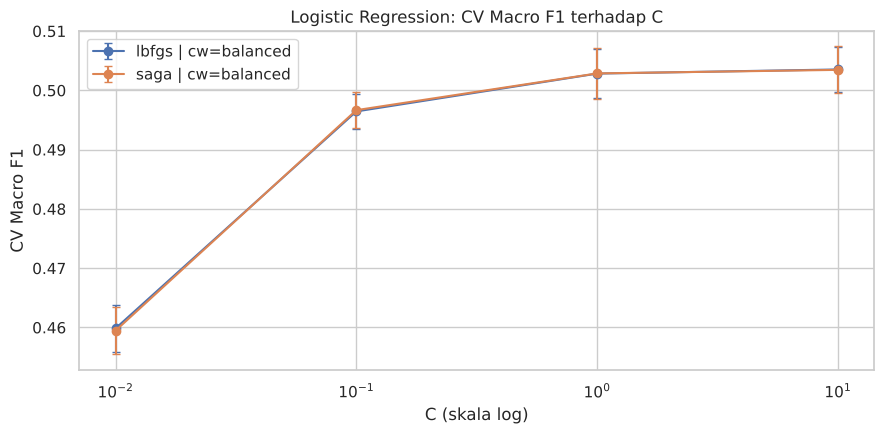

In [28]:
fig, ax = plt.subplots(figsize=(9, 4.5))
plot_df = lr_cv_results.copy()
plot_df["konfigurasi"] = plot_df["param_clf__solver"].astype(str) + " | cw=" + plot_df["param_clf__class_weight"].astype(str)
for label, grp in plot_df.groupby("konfigurasi"):
    grp = grp.sort_values("param_clf__C")
    ax.errorbar(grp["param_clf__C"].astype(float), grp["mean_test_score"], yerr=grp["std_test_score"],
                marker="o", capsize=3, label=label)
ax.set_xscale("log")
ax.set_xlabel("C (skala log)")
ax.set_ylabel("CV Macro F1")
ax.set_title("Logistic Regression: CV Macro F1 terhadap C")
ax.legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "lr_cv_results.png", dpi=120)
plt.show()

**Interpretasi:** grafik memperlihatkan sensitivitas Macro F1 terhadap regularisasi dan pengaruh `class_weight`. Jika garis `balanced` berada di atas `None`, pembobotan kelas membantu kelas minoritas. Selisih antara `mean_train_score` dan `mean_test_score` pada tabel di atas memberi indikasi awal overfitting.

### 10.3. Evaluasi Logistic Regression (Tuned)

Waktu training (seluruh X_train): 65.5 s | iterasi: 576/1000 | ConvergenceWarning: 0


,Strategi,Data Latih (n),CV Macro F1,Valid Accuracy,Valid Macro F1,Valid Weighted F1,Valid Precision (macro),Valid Recall (macro),Valid Log Loss,Waktu Training (s),Waktu Prediksi (s),Kandidat Final,Catatan
Model,,,,,,,,,,,,,
Logistic Regression,Multinomial (softmax),426772,0.5035,0.5424,0.512,0.5474,0.5032,0.5304,1.0842,65.5181,0.2479,True,"tuned: {'clf__C': 10.0, 'clf__class_weight': '..."


Classification report Logistic Regression (validation):


,precision,recall,f1-score,support
1,0.5387,0.7427,0.6245,11034.0000
2,0.3206,0.3835,0.3492,12216.0000
3,0.3966,0.3964,0.3965,19098.0000
4,0.4909,0.4808,0.4858,25738.0000
5,0.7690,0.6487,0.7038,38607.0000
accuracy,0.5424,0.5424,0.5424,0.5424
macro avg,0.5032,0.5304,0.5120,106693.0000
weighted avg,0.5601,0.5424,0.5474,106693.0000


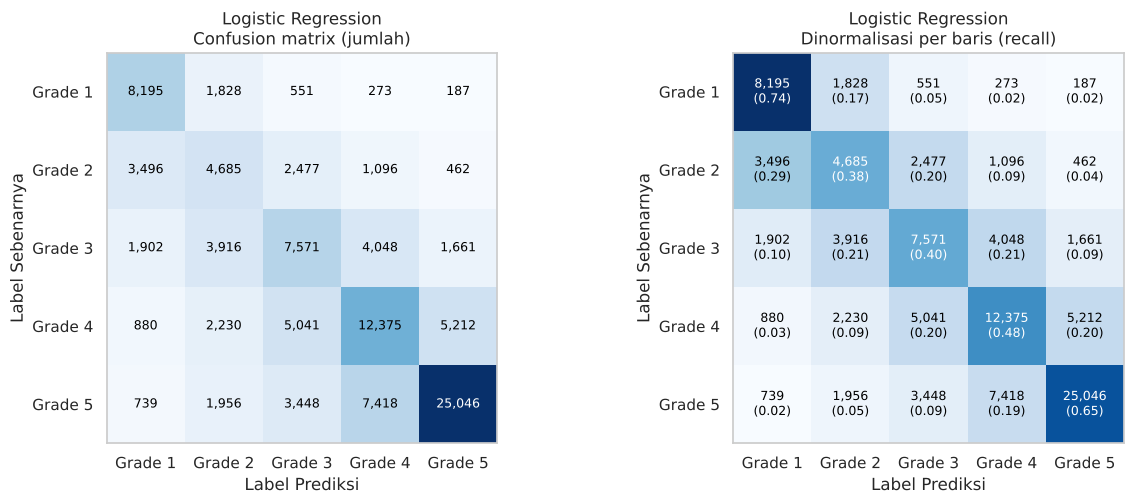

In [29]:
lr_best = Pipeline([
    ("preprocess", make_preprocessor()),
    ("clf", LogisticRegression(max_iter=LR_MAX_ITER, random_state=SEED)),
]).set_params(**lr_best_params)

lr_time, lr_conv = fit_and_report_warnings(lr_best, X_train, y_train)
lr_iter = int(np.max(lr_best.named_steps["clf"].n_iter_))
print(f"Waktu training (seluruh X_train): {lr_time:.1f} s | iterasi: {lr_iter}/{LR_MAX_ITER} | ConvergenceWarning: {lr_conv}")

y_pred_lr, lr_pred_time = timed_predict(lr_best.predict, X_valid)
record_result(
    "Logistic Regression", "Multinomial (softmax)", y_valid, y_pred_lr, lr_time, lr_pred_time,
    n_train=len(X_train), cv_macro_f1=lr_best_cv,
    y_proba=lr_best.predict_proba(X_valid), proba_labels=lr_best.classes_,
    note=f"tuned: {lr_best_params}",
)
fitted_models["Logistic Regression"] = {"predict": lr_best.predict, "X_fit": X_train, "y_fit": y_train}

lr_report = report_table(y_valid, y_pred_lr, "Classification report Logistic Regression (validation):")
show_confusion_matrices(y_valid, y_pred_lr, "Logistic Regression", "cm_logreg.png");

## 11. Support Vector Machine: One-vs-All (OvA) vs One-vs-One (OvO)

### 11.1. Konsep

SVM biner mencari hyperplane dengan margin terbesar antara dua kelas. Untuk **K** kelas, dibutuhkan strategi dekomposisi:

| Aspek | One-vs-All / One-vs-Rest (OvA) | One-vs-One (OvO) |
|---|---|---|
| Jumlah classifier biner | **K** (di sini K = 5 → 5 classifier) | **K(K−1)/2** (di sini 5·4/2 = **10** classifier) |
| Data per classifier | Seluruh data latih (1 kelas vs sisanya) | Hanya sampel dari 2 kelas |
| Prediksi | Kelas dengan skor keputusan tertinggi | Voting dari semua pasangan |
| Kelebihan | Lebih sedikit model, sederhana | Setiap subproblem lebih kecil dan seimbang. Cocok untuk kernel SVM karena biaya SVC naik superlinear terhadap n |
| Kekurangan | Setiap subproblem tidak seimbang (1 kelas vs 4 kelas). Skor antar-model tidak selalu terkalibrasi | Jumlah model bertambah kuadratik terhadap K. Bisa terjadi seri saat voting |

Jumlah classifier yang lebih banyak (OvO) **belum tentu** menghasilkan performa yang lebih baik. Hal ini harus dibuktikan melalui eksperimen. Perlu juga dibedakan antara **strategi multikelas** (OvA/OvO) dan **algoritma dasar** (SVC). Keduanya memakai estimator dasar `SVC` yang sama. Perlu dicatat bahwa `SVC` di scikit-learn secara internal sudah memakai OvO, sehingga di sini keduanya dibungkus secara eksplisit dengan `OneVsRestClassifier` dan `OneVsOneClassifier` agar strateginya jelas dan dapat dibandingkan.

### 11.2. Kendala Komputasi dan Desain Eksperimen

Waktu pelatihan `SVC` (libsvm) tumbuh sekitar O(n²)–O(n³) terhadap jumlah sampel, dan waktu prediksinya sebanding dengan jumlah support vector. Melatih SVC pada ratusan ribu baris tidak realistis dalam batas waktu sesi Kaggle. Oleh karena itu:

1. **SVC OvA dan OvO** dilatih pada **subset stratified yang sama** dari `X_train` (`SVM_TRAIN_SIZE` baris, `random_state=SEED`). Keduanya dievaluasi pada **seluruh** `X_valid` yang sama.
2. Tuning (`kernel`, `C`, `class_weight`) dilakukan dengan `GridSearchCV` + `StratifiedKFold(SVM_CV_FOLDS)` pada subset yang lebih kecil (`SVM_TUNE_SIZE`), secara terpisah untuk OvA dan OvO.
3. Sebagai pembanding skalabel, **`LinearSVC` OvA dan OvO** dilatih pada **seluruh** `X_train`. Hasil subset belum tentu mewakili performa SVM yang dilatih dengan seluruh data, dan pembanding ini membantu menilai seberapa besar pengaruhnya.

Mengikuti alur kode referensi: scaler/preprocessor di-fit **sekali** pada data training SVM, lalu data training dan validation ditransformasi dengan preprocessor yang sama (tanpa fit ulang pada validation). Selanjutnya `SVC` dibungkus `OneVsRestClassifier` dan `OneVsOneClassifier`, dilatih pada data yang sama, dan diprediksi pada data validation yang sama.

In [30]:
X_svm_train, y_svm_train = stratified_subset(X_train, y_train, SVM_TRAIN_SIZE)
X_svm_tune, y_svm_tune = stratified_subset(X_svm_train, y_svm_train, SVM_TUNE_SIZE)
print(f"Subset training SVM : {X_svm_train.shape} (random_state={SEED})")
print(f"Subset tuning SVM   : {X_svm_tune.shape}")
display(pd.DataFrame({
    "X_train (%)": (y_train.value_counts(normalize=True).sort_index() * 100).round(2),
    "subset SVM (%)": (y_svm_train.value_counts(normalize=True).sort_index() * 100).round(2),
}))

Subset training SVM : (20000, 15) (random_state=123)
Subset tuning SVM   : (6000, 15)


,X_train (%),subset SVM (%)
damage_grade,,
1,10.34,10.34
2,11.45,11.45
3,17.90,17.90
4,24.12,24.12
5,36.19,36.18


### 11.3. Hyperparameter Tuning SVC (OvA dan OvO)

Ruang pencarian dibuat ringkas agar realistis:

- `kernel`: `linear` (batas keputusan linear) dan `rbf` (non-linear).
- `C`: 0.1, 1, 10. `C` kecil berarti margin lebih lebar dan regularisasi lebih kuat.
- `class_weight`: `None` atau `balanced`.
- `gamma="scale"` (default scikit-learn, disesuaikan dengan varians fitur) dipakai tetap untuk RBF, karena menambah dimensi `gamma` akan melipatgandakan jumlah fitting SVC yang mahal.

Setiap strategi dituning secara terpisah dengan prosedur yang sama, sehingga perbandingannya adil.

Jika muncul `ConvergenceWarning: Solver terminated early (max_iter=...)`, terutama untuk kernel `linear`, artinya libsvm berhenti pada batas iterasi `SVM_MAX_ITER` sebelum optimasi selesai. Hal ini umum terjadi bila kelas saling tumpang tindih. Model tetap dapat dipakai, tetapi solusinya bersifat aproksimasi. Warning ini sengaja ditampilkan, tidak disembunyikan. Batas dapat dinaikkan dengan konsekuensi waktu yang lebih lama, dan pembanding `LinearSVC` di bagian 11.6 memberi solusi linear yang konvergen.

In [31]:
def make_svc():
    return SVC(kernel="rbf", gamma="scale", cache_size=1000, max_iter=SVM_MAX_ITER, random_state=SEED)


svm_param_grid = {
    "clf__estimator__kernel": ["linear", "rbf"],
    "clf__estimator__C": [0.1, 1.0, 10.0],
    "clf__estimator__class_weight": [None, "balanced"],
}
svm_cv = StratifiedKFold(n_splits=SVM_CV_FOLDS, shuffle=True, random_state=SEED)

svm_search_results = {}
for strategy_name, wrapper in [("OvA", OneVsRestClassifier), ("OvO", OneVsOneClassifier)]:
    search = GridSearchCV(
        Pipeline([("preprocess", make_preprocessor()), ("clf", wrapper(make_svc()))]),
        param_grid=svm_param_grid,
        scoring="f1_macro",
        cv=svm_cv,
        n_jobs=-1,
        refit=False,
    )
    print(f"\nTuning SVC {strategy_name} ...")
    tune_time, _ = fit_and_report_warnings(search, X_svm_tune, y_svm_tune)
    cv_df = pd.DataFrame(search.cv_results_)
    svm_search_results[strategy_name] = {
        "best_params": {k.replace("clf__estimator__", ""): v for k, v in search.best_params_.items()},
        "best_cv": search.best_score_,
        "best_cv_std": cv_df.loc[search.best_index_, "std_test_score"],
        "tune_time": tune_time,
        "cv_results": cv_df,
    }
    print(f"Waktu tuning {strategy_name}: {tune_time:.1f} s")
    print(f"Parameter terbaik {strategy_name}:", svm_search_results[strategy_name]["best_params"])
    print(f"CV Macro F1 terbaik {strategy_name}: {search.best_score_:.4f} ± {svm_search_results[strategy_name]['best_cv_std']:.4f}")

# Parameter bersama untuk perbandingan terkontrol OvA vs OvO (bagian 11.5b):
# kombinasi dengan rata-rata CV Macro F1 tertinggi dari kedua strategi. Hanya memakai CV pada data training.
_param_cols = [c for c in svm_search_results["OvA"]["cv_results"].columns if c.startswith("param_")]
_cv_both = svm_search_results["OvA"]["cv_results"][_param_cols + ["mean_test_score"]].merge(
    svm_search_results["OvO"]["cv_results"][_param_cols + ["mean_test_score"]],
    on=_param_cols, suffixes=("_ova", "_ovo"),
)
_cv_both["mean_both"] = (_cv_both["mean_test_score_ova"] + _cv_both["mean_test_score_ovo"]) / 2
_best_row = _cv_both.loc[_cv_both["mean_both"].idxmax()]
shared_svm_params = {c.replace("param_clf__estimator__", ""): _best_row[c] for c in _param_cols}
shared_svm_params = {k: (v.item() if hasattr(v, "item") else v) for k, v in shared_svm_params.items()}
shared_svm_params = {k: (None if isinstance(v, float) and np.isnan(v) else v) for k, v in shared_svm_params.items()}
print("\nParameter SVC bersama (rata-rata CV OvA & OvO tertinggi):", shared_svm_params,
      f"| CV OvA {_best_row['mean_test_score_ova']:.4f}, CV OvO {_best_row['mean_test_score_ovo']:.4f}")


Tuning SVC OvA ...


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=200000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=200000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=200000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=200000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


...

/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=200000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=200000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=200000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


/usr/local/lib/python3.13/dist-packages/sklearn/svm/_base.py:337: ConvergenceWarning: Solver terminated early (max_iter=200000).  Consider pre-processing your data with StandardScaler or MinMaxScaler.
  warnings.warn(


Waktu tuning OvO: 45.5 s
Parameter terbaik OvO: {'C': 1.0, 'class_weight': 'balanced', 'kernel': 'linear'}
CV Macro F1 terbaik OvO: 0.4235 ± 0.0104

Parameter SVC bersama (rata-rata CV OvA & OvO tertinggi): {'C': 1.0, 'class_weight': 'balanced', 'kernel': 'rbf'} | CV OvA 0.4315, CV OvO 0.4184


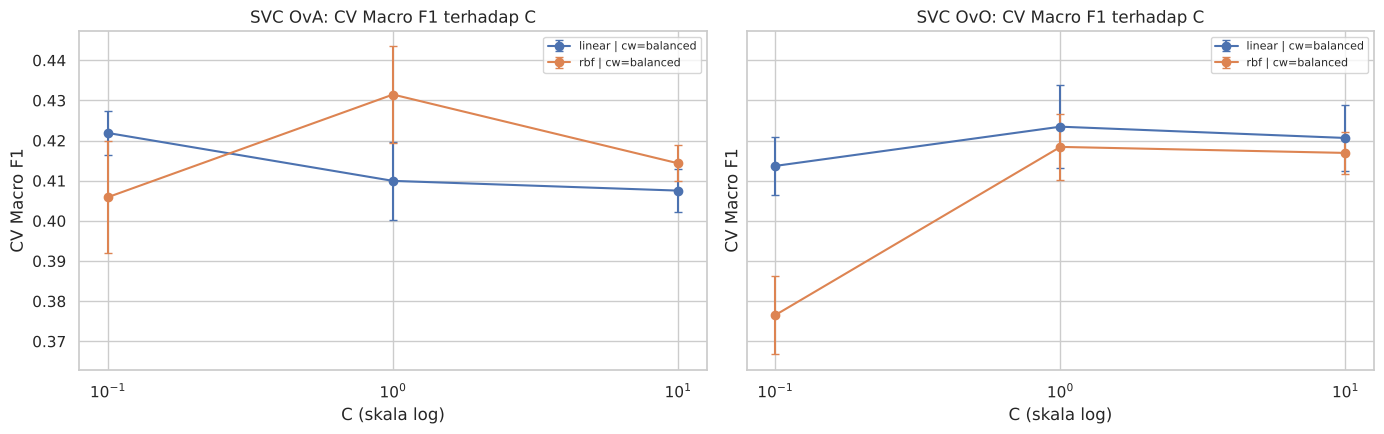

In [32]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, (strategy_name, res) in zip(axes, svm_search_results.items()):
    cv_df = res["cv_results"].copy()
    cv_df["konfigurasi"] = cv_df["param_clf__estimator__kernel"].astype(str) + " | cw=" + cv_df["param_clf__estimator__class_weight"].astype(str)
    for label, grp in cv_df.groupby("konfigurasi"):
        grp = grp.sort_values("param_clf__estimator__C")
        ax.errorbar(grp["param_clf__estimator__C"].astype(float), grp["mean_test_score"], yerr=grp["std_test_score"],
                    marker="o", capsize=3, label=label)
    ax.set_xscale("log")
    ax.set_title(f"SVC {strategy_name}: CV Macro F1 terhadap C")
    ax.set_xlabel("C (skala log)")
    ax.set_ylabel("CV Macro F1")
    ax.legend(fontsize=8)
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "svm_cv_results.png", dpi=120)
plt.show()

### 11.4. Training dan Prediksi SVC OvA vs OvO

Alur berikut mengikuti struktur kode referensi: preprocessor (termasuk `StandardScaler` untuk fitur numerik) di-fit **sekali** pada `X_svm_train`, kemudian `X_svm_train` dan `X_valid` ditransformasi. Kedua model dilatih pada matriks training yang sama dan diprediksi pada matriks validation yang sama.

In [33]:
svm_preprocessor = make_preprocessor()
X_svm_train_t = svm_preprocessor.fit_transform(X_svm_train)   # fit hanya pada data training SVM
X_valid_svm_t = svm_preprocessor.transform(X_valid)           # validation hanya di-transform
print("Matriks training SVM:", X_svm_train_t.shape, "| sparse:", sparse.issparse(X_svm_train_t))
print("Matriks validation  :", X_valid_svm_t.shape)

ova_params = svm_search_results["OvA"]["best_params"]
ovo_params = svm_search_results["OvO"]["best_params"]

ova_classifier = OneVsRestClassifier(make_svc().set_params(**ova_params))
ova_train_time, ova_conv = fit_and_report_warnings(ova_classifier, X_svm_train_t, y_svm_train)
y_pred_ova, ova_pred_time = timed_predict(ova_classifier.predict, X_valid_svm_t)

ovo_classifier = OneVsOneClassifier(make_svc().set_params(**ovo_params))
ovo_train_time, ovo_conv = fit_and_report_warnings(ovo_classifier, X_svm_train_t, y_svm_train)
y_pred_ovo, ovo_pred_time = timed_predict(ovo_classifier.predict, X_valid_svm_t)

svm_structure = pd.DataFrame({
    "Strategi": ["OvA (OneVsRestClassifier)", "OvO (OneVsOneClassifier)"],
    "Parameter": [ova_params, ovo_params],
    "Jumlah classifier biner": [len(ova_classifier.estimators_), len(ovo_classifier.estimators_)],
    "Rumus": [f"K = {N_CLASSES}", f"K(K-1)/2 = {N_CLASSES * (N_CLASSES - 1) // 2}"],
    "Total support vector": [sum(len(e.support_) for e in ova_classifier.estimators_),
                             sum(len(e.support_) for e in ovo_classifier.estimators_)],
    "Waktu training (s)": [ova_train_time, ovo_train_time],
    "Waktu prediksi (s)": [ova_pred_time, ovo_pred_time],
    "ConvergenceWarning": [ova_conv, ovo_conv],
})
display(svm_structure.round(2))

Matriks training SVM: (20000, 668) | sparse: True
Matriks validation  : (106693, 668)


,Strategi,Parameter,Jumlah classifier biner,Rumus,Total support vector,Waktu training (s),Waktu prediksi (s),ConvergenceWarning
0,OvA (OneVsRestClassifier),"{'C': 1.0, 'class_weight': 'balanced', 'kernel...",5,K = 5,59832,164.71,417.28,0
1,OvO (OneVsOneClassifier),"{'C': 1.0, 'class_weight': 'balanced', 'kernel...",10,K(K-1)/2 = 10,40421,44.28,547.43,0


### 11.5. Evaluasi dan Perbandingan OvA vs OvO

In [34]:
record_result(
    "SVM OvA", "One-vs-All (SVC)", y_valid, y_pred_ova, ova_train_time, ova_pred_time,
    n_train=len(X_svm_train), cv_macro_f1=svm_search_results["OvA"]["best_cv"],
    note=f"subset {len(X_svm_train):,}; {ova_params}",
)
record_result(
    "SVM OvO", "One-vs-One (SVC)", y_valid, y_pred_ovo, ovo_train_time, ovo_pred_time,
    n_train=len(X_svm_train), cv_macro_f1=svm_search_results["OvO"]["best_cv"],
    note=f"subset {len(X_svm_train):,}; {ovo_params}",
)
fitted_models["SVM OvA"] = {"predict": lambda X_in: ova_classifier.predict(svm_preprocessor.transform(X_in)),
                            "X_fit": X_svm_train, "y_fit": y_svm_train}
fitted_models["SVM OvO"] = {"predict": lambda X_in: ovo_classifier.predict(svm_preprocessor.transform(X_in)),
                            "X_fit": X_svm_train, "y_fit": y_svm_train}

ova_report = report_table(y_valid, y_pred_ova, "Classification report SVM OvA (validation):")
ovo_report = report_table(y_valid, y_pred_ovo, "Classification report SVM OvO (validation):")

,Strategi,Data Latih (n),CV Macro F1,Valid Accuracy,Valid Macro F1,Valid Weighted F1,Valid Precision (macro),Valid Recall (macro),Valid Log Loss,Waktu Training (s),Waktu Prediksi (s),Kandidat Final,Catatan
Model,,,,,,,,,,,,,
SVM OvA,One-vs-All (SVC),20000,0.4315,0.5144,0.4788,0.5203,0.476,0.4838,NaN,164.7098,417.2764,True,"subset 20,000; {'C': 1.0, 'class_weight': 'bal..."


,Strategi,Data Latih (n),CV Macro F1,Valid Accuracy,Valid Macro F1,Valid Weighted F1,Valid Precision (macro),Valid Recall (macro),Valid Log Loss,Waktu Training (s),Waktu Prediksi (s),Kandidat Final,Catatan
Model,,,,,,,,,,,,,
SVM OvO,One-vs-One (SVC),20000,0.4235,0.5019,0.4597,0.5038,0.4515,0.4824,NaN,44.2765,547.4258,True,"subset 20,000; {'C': 1.0, 'class_weight': 'bal..."


Classification report SVM OvA (validation):


,precision,recall,f1-score,support
1,0.5375,0.5932,0.5640,11034.0000
2,0.3028,0.3334,0.3174,12216.0000
3,0.3530,0.3877,0.3695,19098.0000
4,0.4473,0.4500,0.4487,25738.0000
5,0.7392,0.6547,0.6944,38607.0000
accuracy,0.5144,0.5144,0.5144,0.5144
macro avg,0.4760,0.4838,0.4788,106693.0000
weighted avg,0.5288,0.5144,0.5203,106693.0000


Classification report SVM OvO (validation):


,precision,recall,f1-score,support
1,0.4621,0.7420,0.5695,11034.0000
2,0.2638,0.2645,0.2641,12216.0000
3,0.3485,0.3458,0.3472,19098.0000
4,0.4418,0.4190,0.4301,25738.0000
5,0.7415,0.6408,0.6875,38607.0000
accuracy,0.5019,0.5019,0.5019,0.5019
macro avg,0.4515,0.4824,0.4597,106693.0000
weighted avg,0.5152,0.5019,0.5038,106693.0000


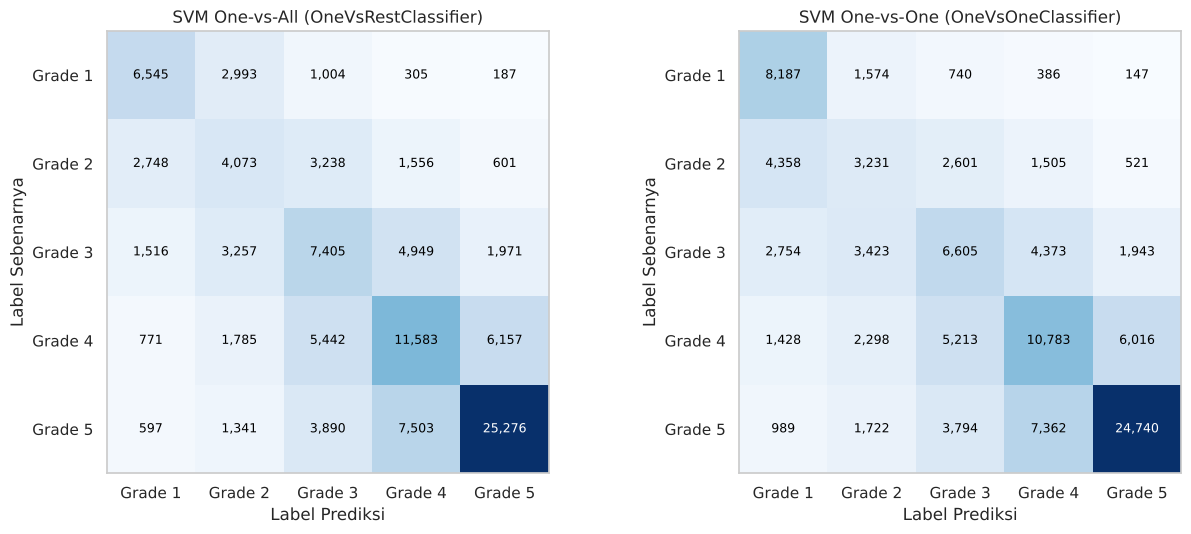

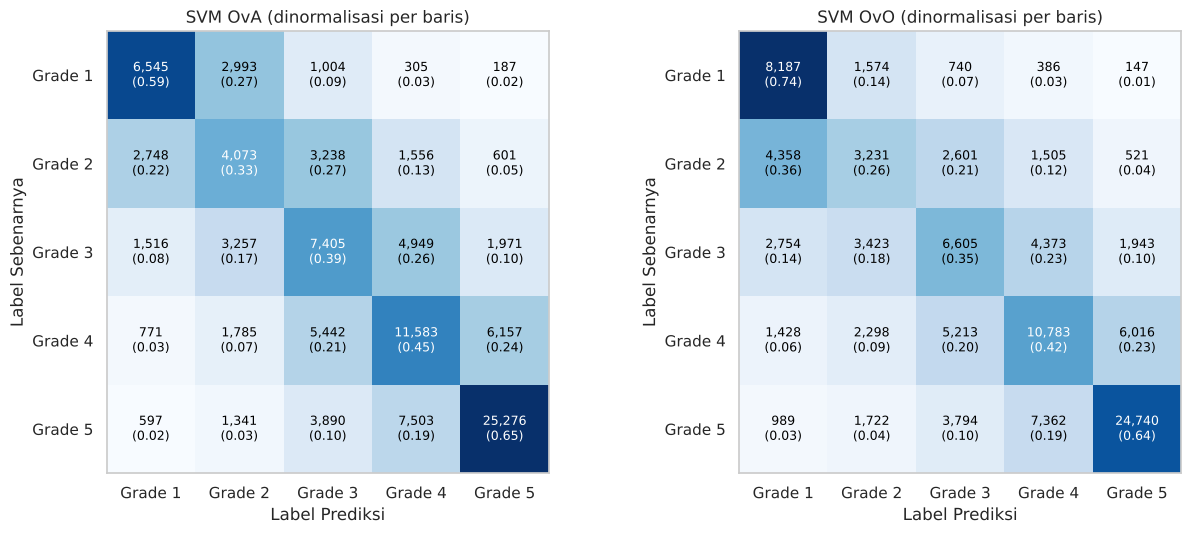

In [35]:
cm_ova = confusion_matrix(y_valid, y_pred_ova, labels=CLASS_LABELS)
cm_ovo = confusion_matrix(y_valid, y_pred_ovo, labels=CLASS_LABELS)

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_confusion_matrix(cm_ova, ORIGINAL_LABELS, "SVM One-vs-All (OneVsRestClassifier)", axes[0])
plot_confusion_matrix(cm_ovo, ORIGINAL_LABELS, "SVM One-vs-One (OneVsOneClassifier)", axes[1])
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cm_svm_ova_vs_ovo.png", dpi=120)
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_confusion_matrix(cm_ova, ORIGINAL_LABELS, "SVM OvA (dinormalisasi per baris)", axes[0], normalize=True)
plot_confusion_matrix(cm_ovo, ORIGINAL_LABELS, "SVM OvO (dinormalisasi per baris)", axes[1], normalize=True)
plt.tight_layout()
plt.show()

In [36]:
ova_vs_ovo = pd.DataFrame(
    [{"Strategi": name, **compute_metrics(y_valid, pred)} for name, pred in [("OvA", y_pred_ova), ("OvO", y_pred_ovo)]]
).drop(columns="log_loss").set_index("Strategi")
ova_vs_ovo["CV Macro F1"] = [svm_search_results["OvA"]["best_cv"], svm_search_results["OvO"]["best_cv"]]
ova_vs_ovo["Waktu training (s)"] = [ova_train_time, ovo_train_time]
ova_vs_ovo["Waktu prediksi (s)"] = [ova_pred_time, ovo_pred_time]
ova_vs_ovo["Jumlah classifier"] = [len(ova_classifier.estimators_), len(ovo_classifier.estimators_)]
print("Perbandingan SVC OvA vs OvO (data validation yang sama):")
display(ova_vs_ovo.round(4))

per_class = pd.DataFrame({
    "F1 OvA": f1_score(y_valid, y_pred_ova, labels=CLASS_LABELS, average=None, zero_division=0),
    "F1 OvO": f1_score(y_valid, y_pred_ovo, labels=CLASS_LABELS, average=None, zero_division=0),
    "Recall OvA": recall_score(y_valid, y_pred_ova, labels=CLASS_LABELS, average=None, zero_division=0),
    "Recall OvO": recall_score(y_valid, y_pred_ovo, labels=CLASS_LABELS, average=None, zero_division=0),
}, index=pd.Index(CLASS_LABELS, name="damage_grade"))
display(per_class.round(4))

agreement = (y_pred_ova == y_pred_ovo).mean()
print(f"Proporsi prediksi OvA dan OvO yang sama: {agreement:.4f}")

Perbandingan SVC OvA vs OvO (data validation yang sama):


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,CV Macro F1,Waktu training (s),Waktu prediksi (s),Jumlah classifier
Strategi,,,,,,,,,
OvA,0.5144,0.4760,0.4838,0.4788,0.5203,0.4315,164.7098,417.2764,5
OvO,0.5019,0.4515,0.4824,0.4597,0.5038,0.4235,44.2765,547.4258,10


,F1 OvA,F1 OvO,Recall OvA,Recall OvO
damage_grade,,,,
1,0.5640,0.5695,0.5932,0.7420
2,0.3174,0.2641,0.3334,0.2645
3,0.3695,0.3472,0.3877,0.3458
4,0.4487,0.4301,0.4500,0.4190
5,0.6944,0.6875,0.6547,0.6408


Proporsi prediksi OvA dan OvO yang sama: 0.7354


### 11.5b. Perbandingan Terkontrol: OvA vs OvO dengan Parameter SVC yang Sama

Pada bagian 11.4, OvA dan OvO dituning secara terpisah, sehingga keduanya bisa memakai kernel atau `C` yang berbeda. Perbedaan skornya pun bisa berasal dari **hyperparameter**, bukan dari **strategi multikelas**. Untuk mengisolasi pengaruh strategi, kedua wrapper dilatih ulang dengan **parameter `SVC` yang sama** (`shared_svm_params`), yaitu kombinasi dengan rata-rata CV Macro F1 OvA dan OvO tertinggi. Pemilihannya hanya memakai CV pada data training. Data training (subset yang sama) dan data validation juga sama. Model yang parameternya kebetulan identik dengan hasil 11.4 tidak dilatih ulang, dan hasilnya dipakai kembali.

Baris ini ditandai `Kandidat Final = False` karena tujuannya analisis, bukan pemilihan model.

OvA: parameter bersama sama dengan hasil tuning, model 11.4 dipakai ulang.


OvO: dilatih dengan parameter bersama (38.3 s training, 642.0 s prediksi).


,Strategi,Data Latih (n),CV Macro F1,Valid Accuracy,Valid Macro F1,Valid Weighted F1,Valid Precision (macro),Valid Recall (macro),Valid Log Loss,Waktu Training (s),Waktu Prediksi (s),Kandidat Final,Catatan
Model,,,,,,,,,,,,,
SVM OvA (param sama),"One-vs-All (SVC, param sama)",20000,NaN,0.5144,0.4788,0.5203,0.476,0.4838,NaN,164.7098,417.2764,False,"subset 20,000; {'C': 1.0, 'class_weight': 'bal..."


,Strategi,Data Latih (n),CV Macro F1,Valid Accuracy,Valid Macro F1,Valid Weighted F1,Valid Precision (macro),Valid Recall (macro),Valid Log Loss,Waktu Training (s),Waktu Prediksi (s),Kandidat Final,Catatan
Model,,,,,,,,,,,,,
SVM OvO (param sama),"One-vs-One (SVC, param sama)",20000,NaN,0.5101,0.4698,0.5117,0.4615,0.4901,NaN,38.3093,641.981,False,"subset 20,000; {'C': 1.0, 'class_weight': 'bal..."


Perbandingan terkontrol (parameter SVC, data latih, dan validation sama): {'C': 1.0, 'class_weight': 'balanced', 'kernel': 'rbf'}


,accuracy,precision_macro,recall_macro,f1_macro,f1_weighted,Jumlah classifier,Waktu training (s),Waktu prediksi (s)
Strategi,,,,,,,,
OvA,0.5144,0.4760,0.4838,0.4788,0.5203,5,164.7098,417.2764
OvO,0.5101,0.4615,0.4901,0.4698,0.5117,10,38.3093,641.9810


Classification report SVM OvA (param sama):


,precision,recall,f1-score,support
1,0.5375,0.5932,0.5640,11034.0000
2,0.3028,0.3334,0.3174,12216.0000
3,0.3530,0.3877,0.3695,19098.0000
4,0.4473,0.4500,0.4487,25738.0000
5,0.7392,0.6547,0.6944,38607.0000
accuracy,0.5144,0.5144,0.5144,0.5144
macro avg,0.4760,0.4838,0.4788,106693.0000
weighted avg,0.5288,0.5144,0.5203,106693.0000


Classification report SVM OvO (param sama):


,precision,recall,f1-score,support
1,0.4891,0.7424,0.5897,11034.0000
2,0.2759,0.2755,0.2757,12216.0000
3,0.3629,0.3447,0.3536,19098.0000
4,0.4374,0.4439,0.4406,25738.0000
5,0.7424,0.6438,0.6896,38607.0000
accuracy,0.5101,0.5101,0.5101,0.5101
macro avg,0.4615,0.4901,0.4698,106693.0000
weighted avg,0.5213,0.5101,0.5117,106693.0000


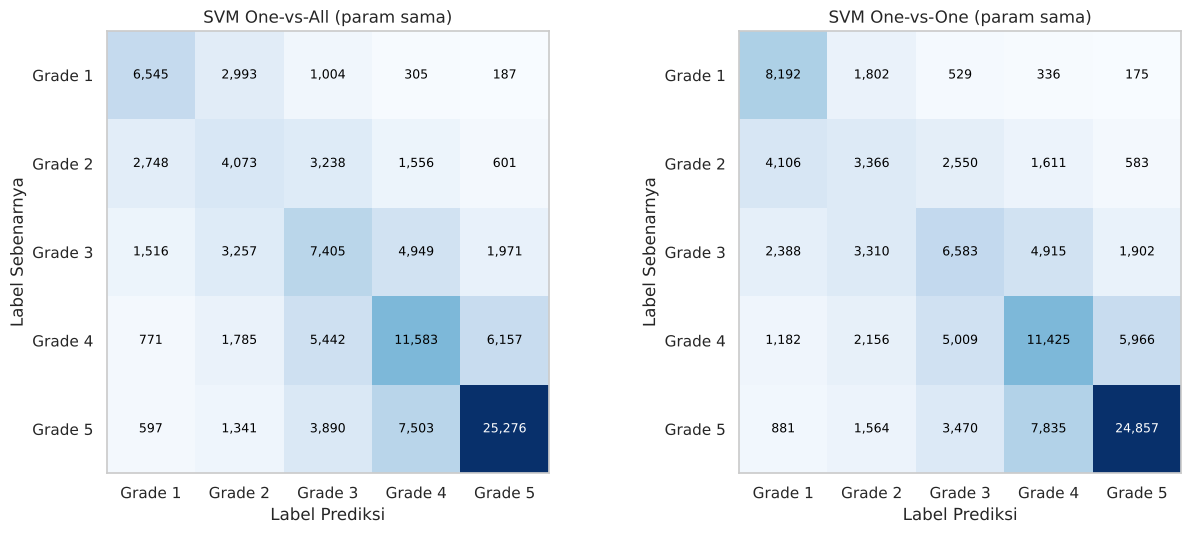

In [37]:
controlled = {}
for strategy_name, wrapper, tuned_params, tuned_clf, tuned_pred, tuned_fit, tuned_pt in [
    ("OvA", OneVsRestClassifier, ova_params, ova_classifier, y_pred_ova, ova_train_time, ova_pred_time),
    ("OvO", OneVsOneClassifier, ovo_params, ovo_classifier, y_pred_ovo, ovo_train_time, ovo_pred_time),
]:
    if tuned_params == shared_svm_params:
        print(f"{strategy_name}: parameter bersama sama dengan hasil tuning, model 11.4 dipakai ulang.")
        controlled[strategy_name] = (tuned_clf, tuned_pred, tuned_fit, tuned_pt)
        continue
    clf = wrapper(make_svc().set_params(**shared_svm_params))
    fit_time, _ = fit_and_report_warnings(clf, X_svm_train_t, y_svm_train)
    pred, pred_time = timed_predict(clf.predict, X_valid_svm_t)
    controlled[strategy_name] = (clf, pred, fit_time, pred_time)
    print(f"{strategy_name}: dilatih dengan parameter bersama ({fit_time:.1f} s training, {pred_time:.1f} s prediksi).")

for strategy_name, label in [("OvA", "One-vs-All (SVC, param sama)"), ("OvO", "One-vs-One (SVC, param sama)")]:
    clf, pred, fit_time, pred_time = controlled[strategy_name]
    record_result(
        f"SVM {strategy_name} (param sama)", label, y_valid, pred, fit_time, pred_time,
        n_train=len(X_svm_train), candidate=False, note=f"subset {len(X_svm_train):,}; {shared_svm_params}",
    )

y_pred_ova_c, y_pred_ovo_c = controlled["OvA"][1], controlled["OvO"][1]
controlled_table = pd.DataFrame(
    [{"Strategi": name, **compute_metrics(y_valid, pred)} for name, pred in [("OvA", y_pred_ova_c), ("OvO", y_pred_ovo_c)]]
).drop(columns="log_loss").set_index("Strategi")
controlled_table["Jumlah classifier"] = [len(controlled["OvA"][0].estimators_), len(controlled["OvO"][0].estimators_)]
controlled_table["Waktu training (s)"] = [controlled["OvA"][2], controlled["OvO"][2]]
controlled_table["Waktu prediksi (s)"] = [controlled["OvA"][3], controlled["OvO"][3]]
print("Perbandingan terkontrol (parameter SVC, data latih, dan validation sama):", shared_svm_params)
display(controlled_table.round(4))

report_table(y_valid, y_pred_ova_c, "Classification report SVM OvA (param sama):")
report_table(y_valid, y_pred_ovo_c, "Classification report SVM OvO (param sama):")

fig, axes = plt.subplots(1, 2, figsize=(13, 5.5))
plot_confusion_matrix(confusion_matrix(y_valid, y_pred_ova_c, labels=CLASS_LABELS), ORIGINAL_LABELS,
                      "SVM One-vs-All (param sama)", axes[0])
plot_confusion_matrix(confusion_matrix(y_valid, y_pred_ovo_c, labels=CLASS_LABELS), ORIGINAL_LABELS,
                      "SVM One-vs-One (param sama)", axes[1])
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "cm_svm_ova_vs_ovo_controlled.png", dpi=120)
plt.show()

### 11.6. Pembanding Skalabel: LinearSVC pada Seluruh Data Training

`LinearSVC` (liblinear) melatih SVM linear dengan biaya yang hampir linear terhadap jumlah sampel, sehingga dapat memakai **seluruh** `X_train`. Model ini dibungkus `OneVsRestClassifier` dan `OneVsOneClassifier` dengan preprocessor yang sama, lalu dievaluasi pada `X_valid` yang sama. `C` dan `class_weight` dituning singkat dengan `StratifiedKFold(3)` pada subset tuning yang sama dengan Logistic Regression.

Perlu dicatat bahwa `LinearSVC` memakai squared hinge loss, sehingga tidak identik dengan `SVC(kernel="linear")`. Model ini berfungsi sebagai pembanding untuk menilai apakah kesimpulan OvA vs OvO berubah bila data penuh digunakan, bukan sebagai pengganti eksperimen SVC.

In [38]:
if RUN_LINEAR_SVM_FULL:
    lsvc_cv = StratifiedKFold(n_splits=3, shuffle=True, random_state=SEED)
    lsvc_grid = {"clf__estimator__C": [0.01, 0.1, 1.0], "clf__estimator__class_weight": [None, "balanced"]}

    for strategy_name, wrapper in [("OvA", OneVsRestClassifier), ("OvO", OneVsOneClassifier)]:
        model_name = f"LinearSVC {strategy_name} (data penuh)"
        base = LinearSVC(dual=False, max_iter=5000, random_state=SEED)
        search = GridSearchCV(
            Pipeline([("preprocess", make_preprocessor()), ("clf", wrapper(base))]),
            param_grid=lsvc_grid, scoring="f1_macro", cv=lsvc_cv, n_jobs=-1, refit=False,
        )
        print(f"\nTuning {model_name} pada {len(X_lr_tune):,} baris ...")
        fit_and_report_warnings(search, X_lr_tune, y_lr_tune)
        best = {k.replace("clf__estimator__", ""): v for k, v in search.best_params_.items()}
        print("Parameter terbaik:", best, f"| CV Macro F1: {search.best_score_:.4f}")

        model = Pipeline([("preprocess", make_preprocessor()), ("clf", wrapper(clone(base).set_params(**best)))])
        train_time, _ = fit_and_report_warnings(model, X_train, y_train)
        y_pred, pred_time = timed_predict(model.predict, X_valid)
        record_result(
            model_name, f"{'One-vs-All' if strategy_name == 'OvA' else 'One-vs-One'} (LinearSVC)",
            y_valid, y_pred, train_time, pred_time, n_train=len(X_train), cv_macro_f1=search.best_score_,
            note=f"pembanding skalabel; {best}",
        )
        fitted_models[model_name] = {"predict": model.predict, "X_fit": X_train, "y_fit": y_train,
                                     "pipeline": model}
else:
    print("RUN_LINEAR_SVM_FULL = False: pembanding LinearSVC dilewati.")


Tuning LinearSVC OvA (data penuh) pada 60,000 baris ...


Parameter terbaik: {'C': 1.0, 'class_weight': 'balanced'} | CV Macro F1: 0.4986


,Strategi,Data Latih (n),CV Macro F1,Valid Accuracy,Valid Macro F1,Valid Weighted F1,Valid Precision (macro),Valid Recall (macro),Valid Log Loss,Waktu Training (s),Waktu Prediksi (s),Kandidat Final,Catatan
Model,,,,,,,,,,,,,
LinearSVC OvA (data penuh),One-vs-All (LinearSVC),426772,0.4986,0.543,0.5081,0.5466,0.4997,0.524,NaN,83.5075,0.3312,True,"pembanding skalabel; {'C': 1.0, 'class_weight'..."



Tuning LinearSVC OvO (data penuh) pada 60,000 baris ...


Parameter terbaik: {'C': 0.1, 'class_weight': 'balanced'} | CV Macro F1: 0.4994


,Strategi,Data Latih (n),CV Macro F1,Valid Accuracy,Valid Macro F1,Valid Weighted F1,Valid Precision (macro),Valid Recall (macro),Valid Log Loss,Waktu Training (s),Waktu Prediksi (s),Kandidat Final,Catatan
Model,,,,,,,,,,,,,
LinearSVC OvO (data penuh),One-vs-One (LinearSVC),426772,0.4994,0.542,0.5114,0.547,0.5024,0.5308,NaN,28.5266,0.3395,True,"pembanding skalabel; {'C': 0.1, 'class_weight'..."


**Cara membaca hasil OvA vs OvO:** bandingkan terlebih dahulu **Macro F1** dan F1 per kelas. Jika selisihnya kecil (misalnya di bawah variasi antar-fold yang ditunjukkan oleh `std` CV), perbedaan tersebut belum cukup kuat untuk menyatakan satu strategi lebih baik, sehingga efisiensi waktu dapat menjadi pertimbangan. Kesimpulan otomatis yang dihitung dari hasil aktual disajikan di bagian 14.

## 12. Neural Network (TensorFlow/Keras)

### 12.1. Desain

Data bersifat **tabular**, sehingga arsitektur yang sesuai adalah **MLP** (lapisan `Dense`), bukan CNN. CNN dirancang untuk data berstruktur spasial seperti gambar, sedangkan urutan kolom pada data tabular tidak memiliki makna spasial.

- **Input:** matriks hasil `make_preprocessor()` yang di-fit pada data training NN.
- **Label:** `LabelEncoder` mengubah 1–5 menjadi 0–4 untuk `sparse_categorical_crossentropy`. Prediksi dikembalikan dengan `inverse_transform`, bukan sekadar ditambah 1.
- **Output:** `Dense(N_CLASSES, activation="softmax")`.
- **Optimizer:** Adam. **Regularisasi:** Dropout dan BatchNormalization.
- **Callback:** `EarlyStopping(restore_best_weights=True)` dan `ReduceLROnPlateau`.
- **Validation internal:** `NN_INTERNAL_VAL_SIZE` dari `X_train` (stratified) dipakai untuk EarlyStopping dan tuning. `X_valid` tetap tidak tersentuh sampai evaluasi akhir.
- **Sparse → dense per batch:** matriks sparse diubah menjadi dense hanya per batch melalui `tf.data`, sehingga seluruh data tidak perlu dimuat dalam bentuk dense di RAM.

OvA/OvO tidak diterapkan pada Neural Network karena softmax sudah memodelkan kelima kelas secara langsung. Neural Network diperlakukan sebagai baseline multikelas standar.

In [39]:
label_encoder = LabelEncoder().fit(y_train)
print("Mapping label NN:", dict(zip(label_encoder.classes_.tolist(), range(len(label_encoder.classes_)))))
assert list(label_encoder.classes_) == CLASS_LABELS

X_nn_train, X_nn_val, y_nn_train, y_nn_val = train_test_split(
    X_train, y_train, test_size=NN_INTERNAL_VAL_SIZE, stratify=y_train, random_state=SEED
)
nn_preprocessor = make_preprocessor()
Xt_nn_train = nn_preprocessor.fit_transform(X_nn_train).astype(np.float32).tocsr()
Xt_nn_val = nn_preprocessor.transform(X_nn_val).astype(np.float32).tocsr()
Xt_nn_valid = nn_preprocessor.transform(X_valid).astype(np.float32).tocsr()
yt_nn_train = label_encoder.transform(y_nn_train)
yt_nn_val = label_encoder.transform(y_nn_val)
N_FEATURES = Xt_nn_train.shape[1]
print("NN train:", Xt_nn_train.shape, "| NN val internal:", Xt_nn_val.shape, "| validation:", Xt_nn_valid.shape)


def make_tf_dataset(X_sp, y_arr=None, batch_size=1024, shuffle=False, seed=SEED):
    n_rows, n_cols = X_sp.shape
    rng = np.random.default_rng(seed)

    def generator():
        idx = np.arange(n_rows)
        if shuffle:
            rng.shuffle(idx)  # urutan berbeda tiap epoch, tetap reproducible
        for start in range(0, n_rows, batch_size):
            batch_idx = idx[start:start + batch_size]
            xb = X_sp[batch_idx]
            xb = xb.toarray() if sparse.issparse(xb) else np.asarray(xb)
            if y_arr is None:
                yield xb.astype(np.float32)
            else:
                yield xb.astype(np.float32), y_arr[batch_idx].astype(np.int32)

    x_spec = tf.TensorSpec(shape=(None, n_cols), dtype=tf.float32)
    signature = x_spec if y_arr is None else (x_spec, tf.TensorSpec(shape=(None,), dtype=tf.int32))
    n_batches = int(np.ceil(n_rows / batch_size))
    ds = tf.data.Dataset.from_generator(generator, output_signature=signature)
    ds = ds.apply(tf.data.experimental.assert_cardinality(n_batches))  # jumlah batch per epoch diketahui
    return ds.prefetch(tf.data.AUTOTUNE)


def build_mlp(n_features, n_classes, hidden_units=(256, 128), dropout=0.3, learning_rate=1e-3):
    inputs = keras.Input(shape=(n_features,))
    x = inputs
    for units in hidden_units:
        x = layers.Dense(units, activation="relu")(x)
        x = layers.BatchNormalization()(x)
        x = layers.Dropout(dropout)(x)
    outputs = layers.Dense(n_classes, activation="softmax")(x)
    model = keras.Model(inputs, outputs)
    model.compile(
        optimizer=keras.optimizers.Adam(learning_rate=learning_rate),
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"],
    )
    return model


def predict_proba_nn(model, X_sp, batch_size=4096):
    return model.predict(make_tf_dataset(X_sp, batch_size=batch_size), verbose=0)


def train_nn(config, X_tr, y_tr, X_va, y_va, max_epochs, patience, verbose=0):
    keras.backend.clear_session()
    tf.random.set_seed(SEED)
    model = build_mlp(N_FEATURES, N_CLASSES, config["hidden_units"], config["dropout"], config["learning_rate"])
    class_weight = None
    if config.get("balanced"):
        weights = compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=y_tr)
        class_weight = dict(enumerate(weights))
    callbacks = [
        keras.callbacks.EarlyStopping(monitor="val_loss", patience=patience, restore_best_weights=True),
        keras.callbacks.ReduceLROnPlateau(monitor="val_loss", factor=0.5, patience=max(1, patience // 2), min_lr=1e-5),
    ]
    start = time.perf_counter()
    history = model.fit(
        make_tf_dataset(X_tr, y_tr, config["batch_size"], shuffle=True),
        validation_data=make_tf_dataset(X_va, y_va, 4096),
        epochs=max_epochs,
        shuffle=False,  # pengacakan sudah dilakukan oleh generator
        class_weight=class_weight,
        callbacks=callbacks,
        verbose=verbose,
    )
    elapsed = time.perf_counter() - start
    best_epoch = int(np.argmin(history.history["val_loss"])) + 1
    return model, history, elapsed, best_epoch

print("Device yang dipakai TensorFlow:", "GPU" if tf.config.list_physical_devices("GPU") else "CPU")

Mapping label NN: {1: 0, 2: 1, 3: 2, 4: 3, 5: 4}


NN train: (384094, 1116) | NN val internal: (42678, 1116) | validation: (106693, 1116)
Device yang dipakai TensorFlow: CPU


### 12.2. Tuning Neural Network

`GridSearchCV` tidak dipakai secara langsung untuk Keras karena integrasinya memerlukan wrapper tambahan. Sebagai gantinya, dilakukan **pencarian manual** pada beberapa konfigurasi (jumlah layer, jumlah neuron, dropout, learning rate, batch size, dan pembobotan kelas). Setiap konfigurasi dilatih pada subset stratified data training NN (`NN_TUNE_SIZE`) dengan EarlyStopping, lalu dinilai dengan **Macro F1 pada validation internal**. Ruang pencarian dibatasi pada konfigurasi yang masuk akal untuk data tabular berdimensi sedang.

In [40]:
NN_SEARCH_SPACE = [
    {"hidden_units": (128, 64), "dropout": 0.2, "learning_rate": 1e-3, "batch_size": 1024, "balanced": False},
    {"hidden_units": (256, 128), "dropout": 0.3, "learning_rate": 1e-3, "batch_size": 1024, "balanced": False},
    {"hidden_units": (256, 128), "dropout": 0.3, "learning_rate": 1e-3, "batch_size": 1024, "balanced": True},
    {"hidden_units": (512, 256, 128), "dropout": 0.3, "learning_rate": 5e-4, "batch_size": 2048, "balanced": True},
]

n_tune = min(NN_TUNE_SIZE, Xt_nn_train.shape[0])
if n_tune < Xt_nn_train.shape[0]:
    tune_idx, _ = train_test_split(np.arange(Xt_nn_train.shape[0]), train_size=n_tune,
                                   stratify=yt_nn_train, random_state=SEED)
else:
    tune_idx = np.arange(Xt_nn_train.shape[0])
print(f"Ukuran data tuning NN: {len(tune_idx):,}")

nn_tuning_rows = []
for i, cfg in enumerate(NN_SEARCH_SPACE):
    model, hist, elapsed, best_epoch = train_nn(
        cfg, Xt_nn_train[tune_idx], yt_nn_train[tune_idx], Xt_nn_val, yt_nn_val,
        max_epochs=NN_TUNE_MAX_EPOCHS, patience=3,
    )
    val_pred = predict_proba_nn(model, Xt_nn_val).argmax(axis=1)
    nn_tuning_rows.append({
        "config_id": i, **{k: str(v) for k, v in cfg.items()},
        "best_epoch": best_epoch,
        "val_loss": float(np.min(hist.history["val_loss"])),
        "val_macro_f1": f1_score(yt_nn_val, val_pred, average="macro"),
        "val_accuracy": accuracy_score(yt_nn_val, val_pred),
        "waktu (s)": elapsed,
    })
    print(f"Config {i}: val Macro F1 = {nn_tuning_rows[-1]['val_macro_f1']:.4f}, best_epoch = {best_epoch}, {elapsed:.1f} s")

nn_tuning_df = pd.DataFrame(nn_tuning_rows).sort_values("val_macro_f1", ascending=False)
display(nn_tuning_df.round(4))
best_nn_config = NN_SEARCH_SPACE[int(nn_tuning_df.iloc[0]["config_id"])]
best_nn_tune_score = float(nn_tuning_df.iloc[0]["val_macro_f1"])
print("Konfigurasi NN terbaik:", best_nn_config)

Ukuran data tuning NN: 150,000


I0000 00:00:1791997412.354382    5698 generator_dataset_op.cc:213] Memory patch applied: M_TRIM_THRESHOLD=128 kb was set.


Config 0: val Macro F1 = 0.5288, best_epoch = 13, 51.8 s


Config 1: val Macro F1 = 0.5331, best_epoch = 13, 68.2 s


Config 2: val Macro F1 = 0.5235, best_epoch = 5, 35.2 s


Config 3: val Macro F1 = 0.5289, best_epoch = 16, 86.5 s


,config_id,hidden_units,dropout,learning_rate,batch_size,balanced,best_epoch,val_loss,val_macro_f1,val_accuracy,waktu (s)
1,1,"(256, 128)",0.3,0.001,1024,False,13,1.0013,0.5331,0.5764,68.1819
3,3,"(512, 256, 128)",0.3,0.0005,2048,True,16,1.0498,0.5289,0.5537,86.4720
0,0,"(128, 64)",0.2,0.001,1024,False,13,1.0061,0.5288,0.5746,51.7605
2,2,"(256, 128)",0.3,0.001,1024,True,5,1.0476,0.5235,0.5546,35.2149


Konfigurasi NN terbaik: {'hidden_units': (256, 128), 'dropout': 0.3, 'learning_rate': 0.001, 'batch_size': 1024, 'balanced': False}


### 12.3. Training Final Neural Network dan Kurva Pelatihan

Konfigurasi terbaik dilatih pada **seluruh** data training NN (`X_train` dikurangi validation internal) dengan EarlyStopping pada validation internal.

Epoch 1/60


376/376 - 11s - 28ms/step - accuracy: 0.5135 - loss: 1.1854 - val_accuracy: 0.5244 - val_loss: 1.1415 - learning_rate: 0.0010


Epoch 2/60


376/376 - 9s - 25ms/step - accuracy: 0.5559 - loss: 1.0513 - val_accuracy: 0.5650 - val_loss: 1.0165 - learning_rate: 0.0010


Epoch 3/60


...

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ input_layer (InputLayer)        │ (None, 1116)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       285,952 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 256)            │         1,024 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 128)            │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 5)              │           645 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 961,553 (3.67 MB)

 Trainable params: 320,261 (1.22 MB)

 Non-trainable params: 768 (3.00 KB)

 Optimizer params: 640,524 (2.44 MB)

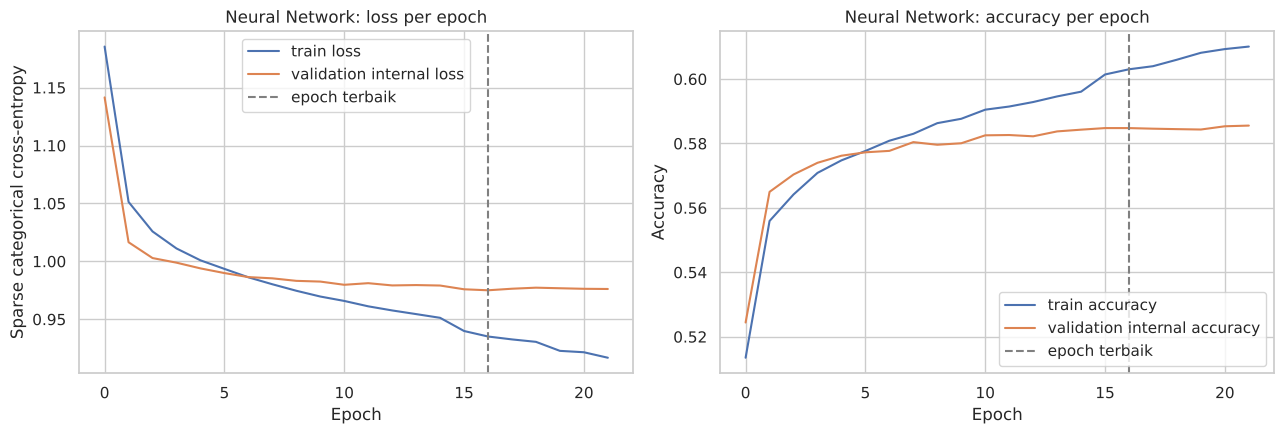

In [41]:
nn_model, nn_history, nn_train_time, nn_best_epoch = train_nn(
    best_nn_config, Xt_nn_train, yt_nn_train, Xt_nn_val, yt_nn_val,
    max_epochs=NN_MAX_EPOCHS, patience=NN_PATIENCE, verbose=2,
)
print(f"Waktu training NN: {nn_train_time:.1f} s | epoch terbaik: {nn_best_epoch} dari {len(nn_history.history['loss'])}")
nn_model.summary()

hist_df = pd.DataFrame(nn_history.history)
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(hist_df["loss"], label="train loss")
axes[0].plot(hist_df["val_loss"], label="validation internal loss")
axes[0].axvline(nn_best_epoch - 1, color="gray", linestyle="--", label="epoch terbaik")
axes[0].set_title("Neural Network: loss per epoch")
axes[0].set_xlabel("Epoch")
axes[0].set_ylabel("Sparse categorical cross-entropy")
axes[0].legend()
axes[1].plot(hist_df["accuracy"], label="train accuracy")
axes[1].plot(hist_df["val_accuracy"], label="validation internal accuracy")
axes[1].axvline(nn_best_epoch - 1, color="gray", linestyle="--", label="epoch terbaik")
axes[1].set_title("Neural Network: accuracy per epoch")
axes[1].set_xlabel("Epoch")
axes[1].set_ylabel("Accuracy")
axes[1].legend()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "nn_training_curves.png", dpi=120)
plt.show()

**Interpretasi kurva:** jika train loss terus turun sementara validation loss naik, model mulai overfitting, dan EarlyStopping mengembalikan bobot dari epoch terbaik. Jika kedua kurva tetap tinggi dan datar, model cenderung underfitting (kapasitas atau informasi fitur kurang). Perlu dicatat bahwa *train loss* dihitung dengan dropout aktif, sehingga bisa sedikit lebih tinggi daripada validation loss.

### 12.4. Evaluasi Neural Network

,Strategi,Data Latih (n),CV Macro F1,Valid Accuracy,Valid Macro F1,Valid Weighted F1,Valid Precision (macro),Valid Recall (macro),Valid Log Loss,Waktu Training (s),Waktu Prediksi (s),Kandidat Final,Catatan
Model,,,,,,,,,,,,,
Neural Network (MLP),Softmax multikelas,384094,NaN,0.5837,0.5423,0.578,0.5434,0.547,0.9798,209.2616,1.0397,True,"config {'hidden_units': (256, 128), 'dropout':..."


Classification report Neural Network (validation):


,precision,recall,f1-score,support
1,0.6172,0.7281,0.6681,11034.0000
2,0.4288,0.3116,0.3609,12216.0000
3,0.4333,0.4364,0.4349,19098.0000
4,0.5190,0.5057,0.5123,25738.0000
5,0.7184,0.7534,0.7355,38607.0000
accuracy,0.5837,0.5837,0.5837,0.5837
macro avg,0.5434,0.5470,0.5423,106693.0000
weighted avg,0.5757,0.5837,0.5780,106693.0000


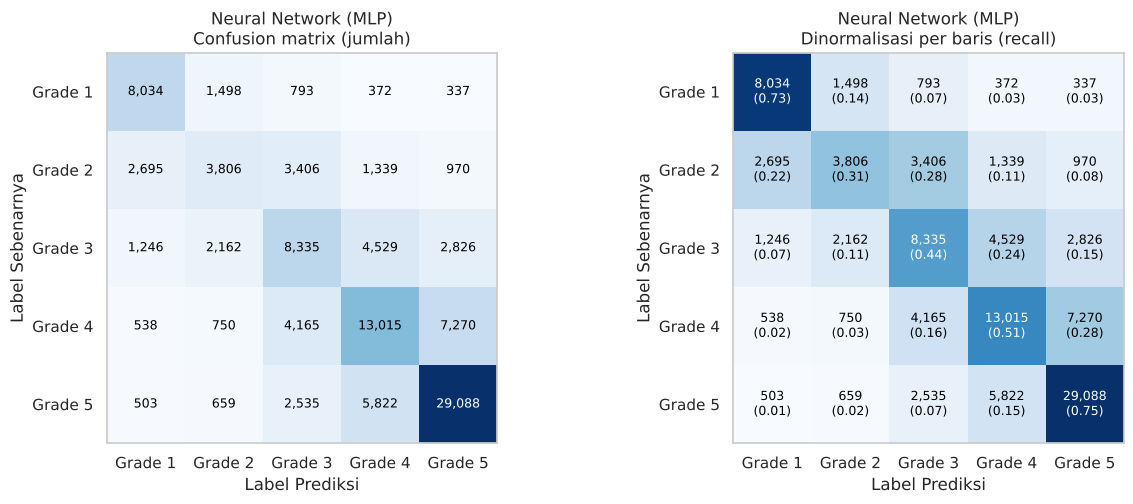

In [42]:
start = time.perf_counter()
nn_valid_proba = predict_proba_nn(nn_model, Xt_nn_valid)
nn_pred_time = time.perf_counter() - start
y_pred_nn = label_encoder.inverse_transform(nn_valid_proba.argmax(axis=1))

record_result(
    "Neural Network (MLP)", "Softmax multikelas", y_valid, y_pred_nn, nn_train_time, nn_pred_time,
    n_train=Xt_nn_train.shape[0], cv_macro_f1=np.nan,
    y_proba=nn_valid_proba, proba_labels=list(label_encoder.classes_),
    note=f"config {best_nn_config}; val internal Macro F1 tuning {best_nn_tune_score:.4f}",
)
fitted_models["Neural Network (MLP)"] = {
    "predict": lambda X_in: label_encoder.inverse_transform(
        predict_proba_nn(nn_model, nn_preprocessor.transform(X_in).astype(np.float32).tocsr()).argmax(axis=1)),
    "X_fit": X_nn_train, "y_fit": y_nn_train,
}

nn_report = report_table(y_valid, y_pred_nn, "Classification report Neural Network (validation):")
show_confusion_matrices(y_valid, y_pred_nn, "Neural Network (MLP)", "cm_nn.png");

## 13. Perbandingan Seluruh Model

Seluruh model dievaluasi pada `X_valid`/`y_valid` yang sama. Kolom **CV Macro F1** berasal dari cross-validation saat tuning, dengan ukuran data yang berbeda per model (lihat `Data Latih (n)` dan bagian 2.5). Neural Network tidak memiliki CV karena dituning dengan validation internal. Log loss hanya diisi untuk model yang menghasilkan probabilitas (Logistic Regression dan Neural Network). SVC/LinearSVC tidak menghasilkan probabilitas tanpa kalibrasi tambahan.

In [43]:
results_df = pd.DataFrame(results).set_index("Model")
results_df = results_df.sort_values("Valid Macro F1", ascending=False)
display(results_df.round(4))
results_df.to_csv(OUTPUT_DIR / "model_comparison.csv")

main_table = results_df[["Strategi", "CV Macro F1", "Valid Accuracy", "Valid Macro F1", "Valid Weighted F1", "Waktu Training (s)"]]
print("Tabel ringkas (Model | Strategi | CV Macro F1 | Valid Accuracy | Valid Macro F1 | Valid Weighted F1 | Waktu):")
display(main_table.round(4))

,Strategi,Data Latih (n),CV Macro F1,Valid Accuracy,Valid Macro F1,Valid Weighted F1,Valid Precision (macro),Valid Recall (macro),Valid Log Loss,Waktu Training (s),Waktu Prediksi (s),Kandidat Final,Catatan
Model,,,,,,,,,,,,,
Neural Network (MLP),Softmax multikelas,384094,NaN,0.5837,0.5423,0.5780,0.5434,0.5470,0.9798,209.2616,1.0397,True,"config {'hidden_units': (256, 128), 'dropout':..."
Logistic Regression,Multinomial (softmax),426772,0.5035,0.5424,0.5120,0.5474,0.5032,0.5304,1.0842,65.5181,0.2479,True,"tuned: {'clf__C': 10.0, 'clf__class_weight': '..."
LinearSVC OvO (data penuh),One-vs-One (LinearSVC),426772,0.4994,0.5420,0.5114,0.5470,0.5024,0.5308,NaN,28.5266,0.3395,True,"pembanding skalabel; {'C': 0.1, 'class_weight'..."
LinearSVC OvA (data penuh),One-vs-All (LinearSVC),426772,0.4986,0.5430,0.5081,0.5466,0.4997,0.5240,NaN,83.5075,0.3312,True,"pembanding skalabel; {'C': 1.0, 'class_weight'..."
LogReg Baseline,Multinomial (softmax),426772,NaN,0.5576,0.5050,0.5471,0.5091,0.5108,1.0386,52.2804,0.3506,False,parameter default
SVM OvA,One-vs-All (SVC),20000,0.4315,0.5144,0.4788,0.5203,0.4760,0.4838,NaN,164.7098,417.2764,True,"subset 20,000; {'C': 1.0, 'class_weight': 'bal..."
SVM OvA (param sama),"One-vs-All (SVC, param sama)",20000,NaN,0.5144,0.4788,0.5203,0.4760,0.4838,NaN,164.7098,417.2764,False,"subset 20,000; {'C': 1.0, 'class_weight': 'bal..."
SVM OvO (param sama),"One-vs-One (SVC, param sama)",20000,NaN,0.5101,0.4698,0.5117,0.4615,0.4901,NaN,38.3093,641.9810,False,"subset 20,000; {'C': 1.0, 'class_weight': 'bal..."
SVM OvO,One-vs-One (SVC),20000,0.4235,0.5019,0.4597,0.5038,0.4515,0.4824,NaN,44.2765,547.4258,True,"subset 20,000; {'C': 1.0, 'class_weight': 'bal..."


Tabel ringkas (Model | Strategi | CV Macro F1 | Valid Accuracy | Valid Macro F1 | Valid Weighted F1 | Waktu):


,Strategi,CV Macro F1,Valid Accuracy,Valid Macro F1,Valid Weighted F1,Waktu Training (s)
Model,,,,,,
Neural Network (MLP),Softmax multikelas,NaN,0.5837,0.5423,0.5780,209.2616
Logistic Regression,Multinomial (softmax),0.5035,0.5424,0.5120,0.5474,65.5181
LinearSVC OvO (data penuh),One-vs-One (LinearSVC),0.4994,0.5420,0.5114,0.5470,28.5266
LinearSVC OvA (data penuh),One-vs-All (LinearSVC),0.4986,0.5430,0.5081,0.5466,83.5075
LogReg Baseline,Multinomial (softmax),NaN,0.5576,0.5050,0.5471,52.2804
SVM OvA,One-vs-All (SVC),0.4315,0.5144,0.4788,0.5203,164.7098
SVM OvA (param sama),"One-vs-All (SVC, param sama)",NaN,0.5144,0.4788,0.5203,164.7098
SVM OvO (param sama),"One-vs-One (SVC, param sama)",NaN,0.5101,0.4698,0.5117,38.3093
SVM OvO,One-vs-One (SVC),0.4235,0.5019,0.4597,0.5038,44.2765


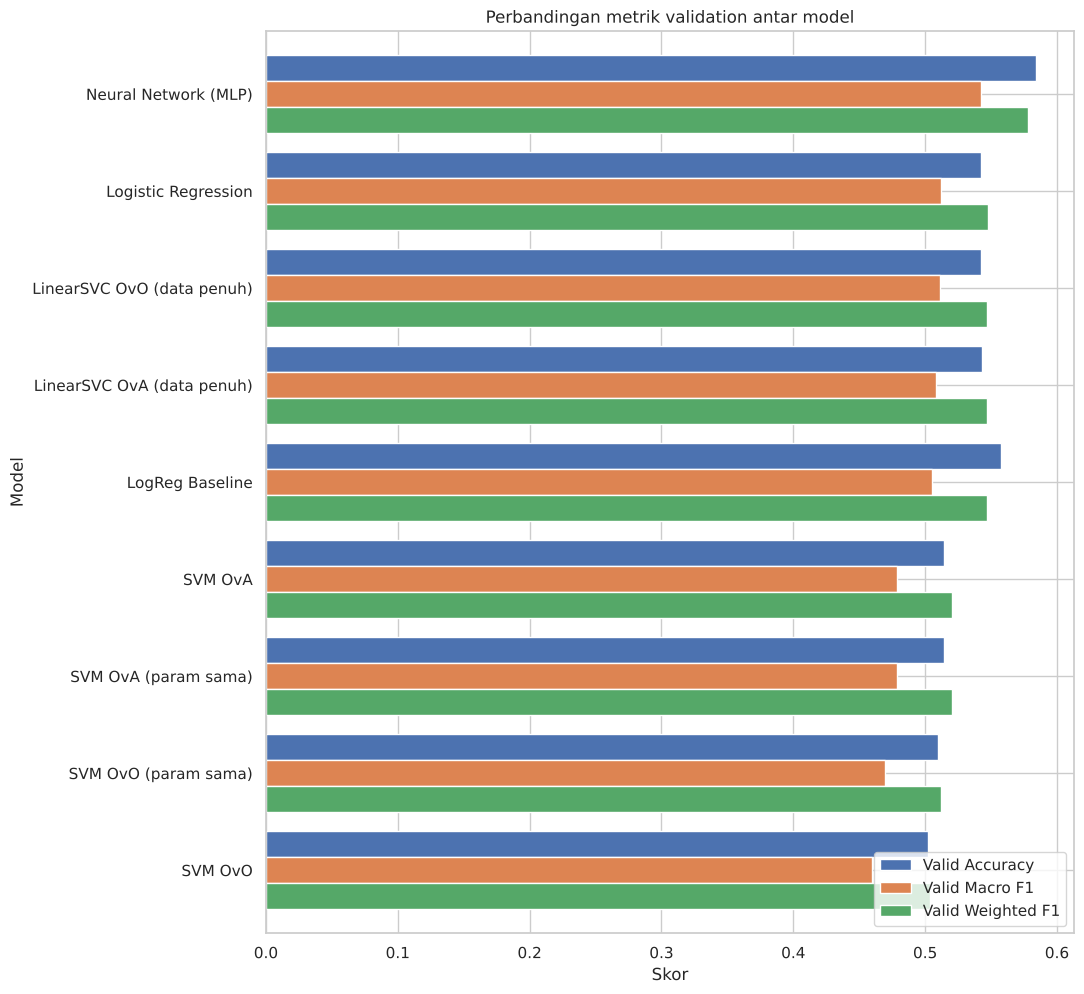

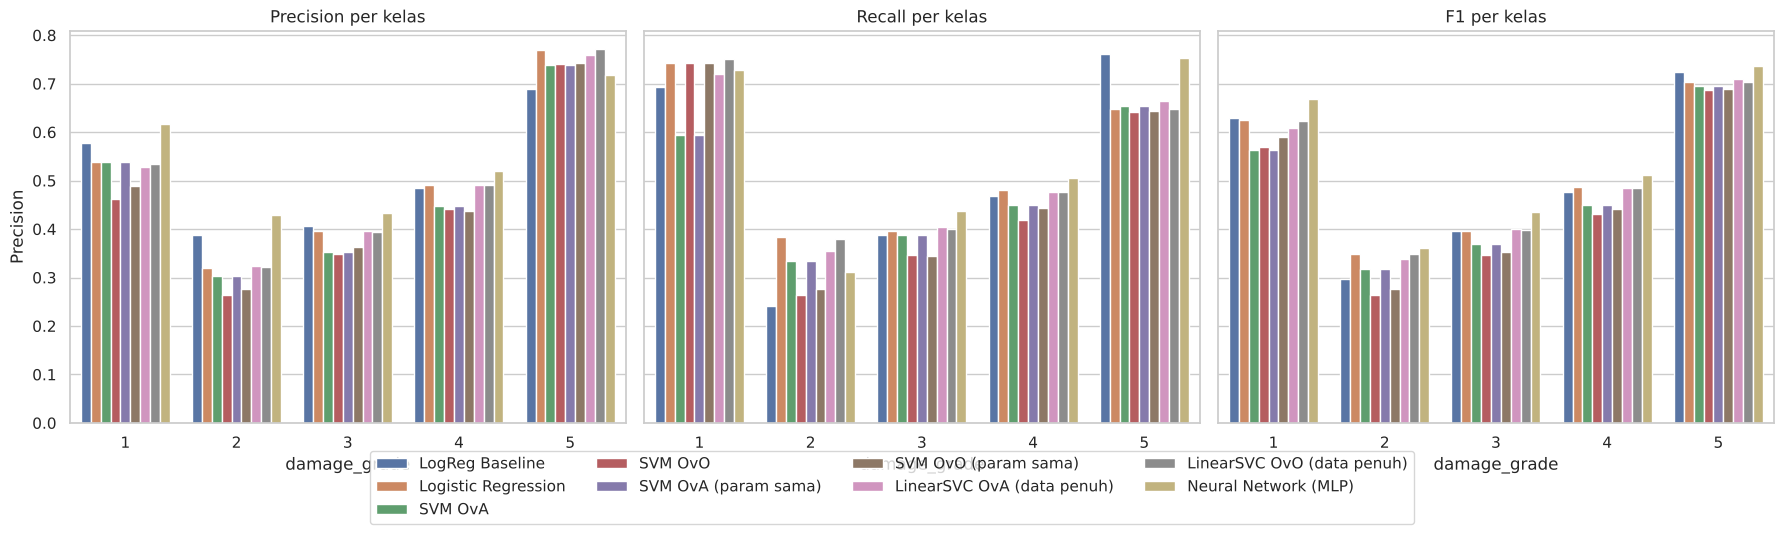

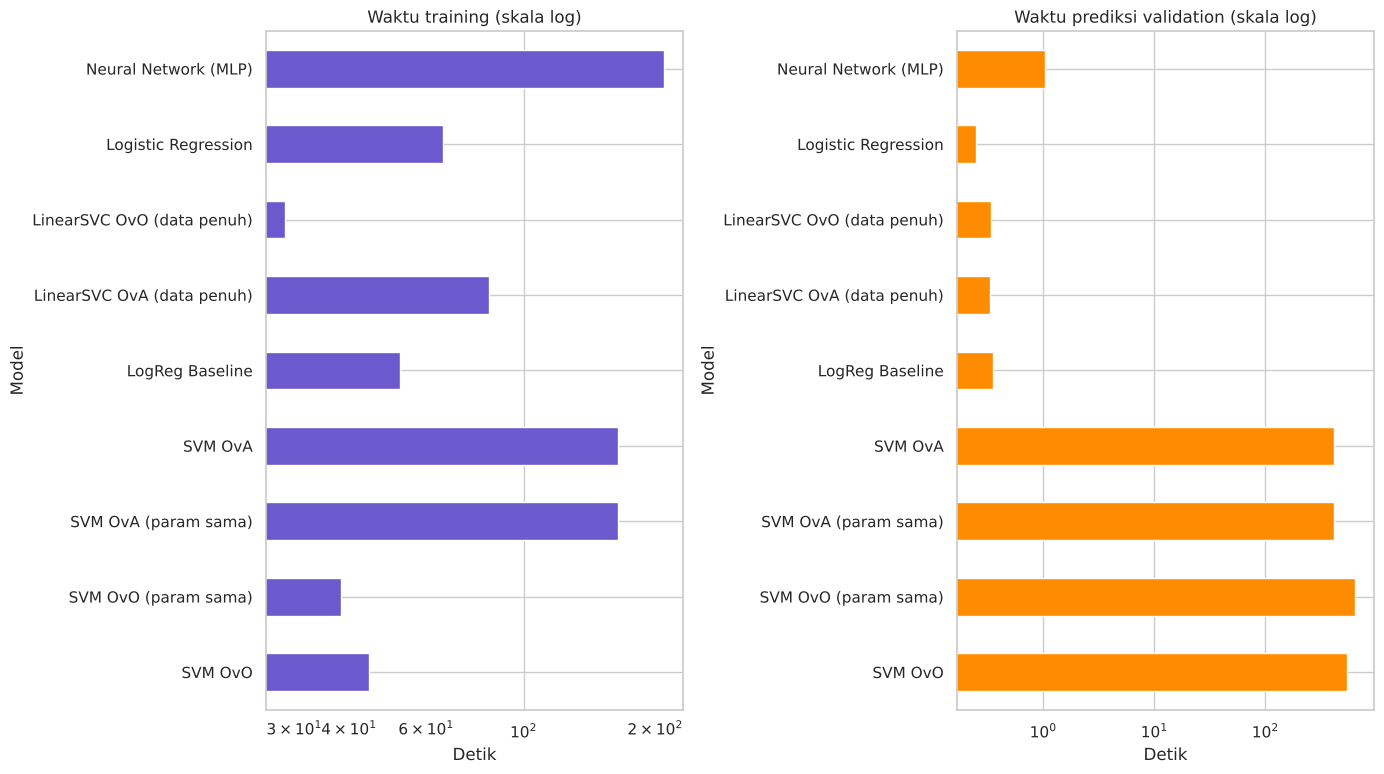

In [44]:
metric_cols = ["Valid Accuracy", "Valid Macro F1", "Valid Weighted F1"]
ax = results_df[metric_cols].plot(kind="barh", figsize=(11, 0.9 * len(results_df) + 2), width=0.8)
ax.set_title("Perbandingan metrik validation antar model")
ax.set_xlabel("Skor")
ax.set_ylabel("Model")
ax.legend(loc="lower right")
ax.invert_yaxis()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_metrics_comparison.png", dpi=120)
plt.show()

per_class_rows = []
for model_name, pred in predictions.items():
    p, r, f, _ = precision_recall_fscore_support(y_valid, pred, labels=CLASS_LABELS, zero_division=0)
    for cls, pi, ri, fi in zip(CLASS_LABELS, p, r, f):
        per_class_rows.append({"Model": model_name, "Kelas": cls, "Precision": pi, "Recall": ri, "F1": fi})
per_class_df = pd.DataFrame(per_class_rows)

fig, axes = plt.subplots(1, 3, figsize=(18, 5), sharey=True)
for ax, metric in zip(axes, ["Precision", "Recall", "F1"]):
    sns.barplot(data=per_class_df, x="Kelas", y=metric, hue="Model", ax=ax)
    ax.set_title(f"{metric} per kelas")
    ax.set_xlabel("damage_grade")
    ax.set_ylabel(metric)
    ax.legend_.remove()
handles, labels_ = axes[0].get_legend_handles_labels()
fig.legend(handles, labels_, loc="lower center", ncol=min(4, len(labels_)), bbox_to_anchor=(0.5, -0.08))
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "per_class_metrics.png", dpi=120, bbox_inches="tight")
plt.show()

fig, axes = plt.subplots(1, 2, figsize=(14, 0.6 * len(results_df) + 2.5))
results_df["Waktu Training (s)"].plot(kind="barh", ax=axes[0], color="slateblue", logx=True)
axes[0].set_title("Waktu training (skala log)")
axes[0].set_xlabel("Detik")
axes[0].invert_yaxis()
results_df["Waktu Prediksi (s)"].plot(kind="barh", ax=axes[1], color="darkorange", logx=True)
axes[1].set_title("Waktu prediksi validation (skala log)")
axes[1].set_xlabel("Detik")
axes[1].invert_yaxis()
plt.tight_layout()
plt.savefig(OUTPUT_DIR / "model_time_comparison.png", dpi=120)
plt.show()

### 13.1. Tabel Khusus Eksperimen OvA vs OvO

Tabel ini memuat model yang dibungkus secara eksplisit dengan OvA/OvO (SVC subset dan LinearSVC data penuh), dengan Neural Network softmax sebagai baseline multikelas standar.

In [45]:
ovx_mask = results_df["Strategi"].str.contains("One-vs") | results_df.index.str.startswith("Neural Network")
ovx_table = results_df.loc[ovx_mask, ["Strategi", "Data Latih (n)", "CV Macro F1", "Valid Macro F1",
                                      "Valid Accuracy", "Valid Weighted F1", "Waktu Training (s)"]]
display(ovx_table.round(4))
ovx_table.to_csv(OUTPUT_DIR / "ova_vs_ovo_comparison.csv")

,Strategi,Data Latih (n),CV Macro F1,Valid Macro F1,Valid Accuracy,Valid Weighted F1,Waktu Training (s)
Model,,,,,,,
Neural Network (MLP),Softmax multikelas,384094,NaN,0.5423,0.5837,0.5780,209.2616
LinearSVC OvO (data penuh),One-vs-One (LinearSVC),426772,0.4994,0.5114,0.5420,0.5470,28.5266
LinearSVC OvA (data penuh),One-vs-All (LinearSVC),426772,0.4986,0.5081,0.5430,0.5466,83.5075
SVM OvA,One-vs-All (SVC),20000,0.4315,0.4788,0.5144,0.5203,164.7098
SVM OvA (param sama),"One-vs-All (SVC, param sama)",20000,NaN,0.4788,0.5144,0.5203,164.7098
SVM OvO (param sama),"One-vs-One (SVC, param sama)",20000,NaN,0.4698,0.5101,0.5117,38.3093
SVM OvO,One-vs-One (SVC),20000,0.4235,0.4597,0.5019,0.5038,44.2765


## 14. Visualisasi dan Interpretasi

Analisis berikut **dihitung langsung dari hasil eksperimen**: model terbaik menurut Macro F1 dan Accuracy, kelas tersulit, pasangan kelas yang paling sering tertukar, serta indikasi overfitting/underfitting (selisih skor training vs validation).

In [46]:
candidates_df = results_df[results_df["Kandidat Final"]]
best_f1_model = candidates_df["Valid Macro F1"].idxmax()
best_acc_model = candidates_df["Valid Accuracy"].idxmax()
print(f"Model dengan Macro F1 tertinggi : {best_f1_model} ({candidates_df.loc[best_f1_model, 'Valid Macro F1']:.4f})")
print(f"Model dengan Accuracy tertinggi : {best_acc_model} ({candidates_df.loc[best_acc_model, 'Valid Accuracy']:.4f})")
print("Model yang sama?", best_f1_model == best_acc_model)

f1_by_class = per_class_df.pivot(index="Kelas", columns="Model", values="F1")
print("\nF1 per kelas (validation):")
display(f1_by_class.round(4))
hardest_class = f1_by_class.mean(axis=1).idxmin()
easiest_class = f1_by_class.mean(axis=1).idxmax()
print(f"Kelas tersulit (rata-rata F1 terendah) : {hardest_class}")
print(f"Kelas termudah (rata-rata F1 tertinggi): {easiest_class}")

cm_best = confusion_matrix(y_valid, predictions[best_f1_model], labels=CLASS_LABELS)
off_diag = cm_best.copy()
np.fill_diagonal(off_diag, 0)
pairs = sorted(
    [(CLASS_LABELS[i], CLASS_LABELS[j], off_diag[i, j], off_diag[i, j] / cm_best[i].sum())
     for i in range(N_CLASSES) for j in range(N_CLASSES) if i != j],
    key=lambda t: t[2], reverse=True,
)[:5]
print(f"\n5 kesalahan terbanyak pada {best_f1_model} (aktual -> prediksi):")
display(pd.DataFrame(pairs, columns=["Aktual", "Prediksi", "Jumlah", "Proporsi dari kelas aktual"]).round(4))

adjacent = sum(c for a, p, c, _ in pairs if abs(a - p) == 1)
print(f"Dari 5 kesalahan terbanyak, {adjacent:,} sampel tertukar dengan kelas bersebelahan (selisih grade 1).")

Model dengan Macro F1 tertinggi : Neural Network (MLP) (0.5423)
Model dengan Accuracy tertinggi : Neural Network (MLP) (0.5837)
Model yang sama? True

F1 per kelas (validation):


Model,LinearSVC OvA (data penuh),LinearSVC OvO (data penuh),LogReg Baseline,Logistic Regression,Neural Network (MLP),SVM OvA,SVM OvA (param sama),SVM OvO,SVM OvO (param sama)
Kelas,,,,,,,,,
1,0.6087,0.6237,0.6301,0.6245,0.6681,0.5640,0.5640,0.5695,0.5897
2,0.3390,0.3476,0.2980,0.3492,0.3609,0.3174,0.3174,0.2641,0.2757
3,0.3999,0.3974,0.3968,0.3965,0.4349,0.3695,0.3695,0.3472,0.3536
4,0.4841,0.4841,0.4766,0.4858,0.5123,0.4487,0.4487,0.4301,0.4406
5,0.7088,0.7040,0.7235,0.7038,0.7355,0.6944,0.6944,0.6875,0.6896


Kelas tersulit (rata-rata F1 terendah) : 2
Kelas termudah (rata-rata F1 tertinggi): 5

5 kesalahan terbanyak pada Neural Network (MLP) (aktual -> prediksi):


,Aktual,Prediksi,Jumlah,Proporsi dari kelas aktual
0,4,5,7270,0.2825
1,5,4,5822,0.1508
2,3,4,4529,0.2371
3,4,3,4165,0.1618
4,2,3,3406,0.2788


Dari 5 kesalahan terbanyak, 25,192 sampel tertukar dengan kelas bersebelahan (selisih grade 1).


In [47]:
fit_rows = []
for model_name, info in fitted_models.items():
    X_fit_s, y_fit_s = stratified_subset(info["X_fit"], info["y_fit"], 20_000)
    train_pred = info["predict"](X_fit_s)
    train_f1 = f1_score(y_fit_s, train_pred, average="macro")
    valid_f1 = results_df.loc[model_name, "Valid Macro F1"]
    gap = train_f1 - valid_f1
    if gap > 0.05:
        status = "indikasi overfitting (gap > 0.05)"
    elif abs(gap) < 0.02:
        status = "skor train ~ valid: tidak overfitting; jika keduanya rendah, indikasi underfitting"
    else:
        status = "gap moderat (0.02-0.05)"
    fit_rows.append({"Model": model_name, "Train Macro F1 (sampel data latih)": train_f1,
                     "Valid Macro F1": valid_f1, "Gap": gap, "Status": status})
fit_df = pd.DataFrame(fit_rows).set_index("Model")
display(fit_df.round(4))

,Train Macro F1 (sampel data latih),Valid Macro F1,Gap,Status
Model,,,,
Logistic Regression,0.5153,0.5120,0.0033,skor train ~ valid: tidak overfitting; jika ke...
SVM OvA,0.6218,0.4788,0.1430,indikasi overfitting (gap > 0.05)
SVM OvO,0.5051,0.4597,0.0454,gap moderat (0.02-0.05)
LinearSVC OvA (data penuh),0.5108,0.5081,0.0027,skor train ~ valid: tidak overfitting; jika ke...
LinearSVC OvO (data penuh),0.5146,0.5114,0.0033,skor train ~ valid: tidak overfitting; jika ke...
Neural Network (MLP),0.5890,0.5423,0.0467,gap moderat (0.02-0.05)


**Catatan interpretasi:**

- **Accuracy vs Macro F1:** jika model dengan Accuracy tertinggi berbeda dari model dengan Macro F1 tertinggi, model tersebut kemungkinan unggul di kelas mayoritas tetapi lemah di kelas minoritas.
- **Kelas bersebelahan:** `damage_grade` bersifat ordinal. Kesalahan antara grade yang bersebelahan (misalnya 2↔3) lebih wajar daripada kesalahan antara grade yang berjauhan (1↔5). Fitur struktural yang tersedia mungkin tidak cukup untuk memisahkan tingkat kerusakan yang berdekatan.
- **Ambang overfitting** (gap 0.05 dan 0.02) hanyalah heuristik untuk membantu membaca hasil, bukan uji statistik.

## 15. Kesimpulan

Kesimpulan di bawah dibentuk otomatis dari tabel hasil, sehingga selalu sesuai dengan eksekusi notebook. Sel ini menjawab pertanyaan analisis: model terbaik, Accuracy vs Macro F1, kelas tersulit, overfitting/underfitting, perbandingan LR vs SVM vs NN, OvA vs OvO, dan sebanding-tidaknya peningkatan performa dengan waktu komputasi.

In [48]:
def fmt(model_name, col="Valid Macro F1"):
    return f"{results_df.loc[model_name, col]:.4f}"


lines = []
lines.append(f"1. Model dengan Macro F1 validation tertinggi adalah {best_f1_model} (Macro F1 = {fmt(best_f1_model)}, "
             f"Accuracy = {fmt(best_f1_model, 'Valid Accuracy')}).")
if best_f1_model == best_acc_model:
    lines.append("2. Model dengan Accuracy tertinggi juga memiliki Macro F1 tertinggi.")
else:
    lines.append(f"2. Model dengan Accuracy tertinggi ({best_acc_model}, {fmt(best_acc_model, 'Valid Accuracy')}) berbeda dari "
                 f"model dengan Macro F1 tertinggi, sehingga Accuracy saja tidak cukup untuk memilih model.")
lines.append(f"3. Kelas tersulit adalah damage_grade {hardest_class} (rata-rata F1 antar-model "
             f"{f1_by_class.loc[hardest_class].mean():.4f}); kelas termudah adalah {easiest_class} "
             f"({f1_by_class.loc[easiest_class].mean():.4f}).")
overfit = fit_df.index[fit_df["Status"].str.startswith("indikasi overfitting")].tolist()
close_fit = fit_df.index[fit_df["Gap"].abs() < 0.02].tolist()
lines.append(f"4. Indikasi overfitting (gap Macro F1 train-valid > 0.05): {overfit if overfit else 'tidak ada'}. "
             f"Model dengan skor train hampir sama dengan valid (gap < 0.02): {close_fit if close_fit else 'tidak ada'}; "
             f"bila skor keduanya rendah (Macro F1 terbaik {candidates_df['Valid Macro F1'].max():.4f}), keterbatasan lebih "
             f"mungkin berasal dari informasi fitur atau kapasitas model (underfitting) daripada overfitting.")

svm_names = [n for n in ["SVM OvA", "SVM OvO"] if n in results_df.index]
best_svm = max(svm_names, key=lambda n: results_df.loc[n, "Valid Macro F1"])
lr_f1 = results_df.loc["Logistic Regression", "Valid Macro F1"]
svm_f1 = results_df.loc[best_svm, "Valid Macro F1"]
lines.append(f"5. Logistic Regression (Macro F1 {lr_f1:.4f}, {results_df.loc['Logistic Regression', 'Waktu Training (s)']:.1f} s, "
             f"{results_df.loc['Logistic Regression', 'Data Latih (n)']:,} baris) vs SVC terbaik {best_svm} "
             f"(Macro F1 {svm_f1:.4f}, {results_df.loc[best_svm, 'Waktu Training (s)']:.1f} s, "
             f"{results_df.loc[best_svm, 'Data Latih (n)']:,} baris): selisih {lr_f1 - svm_f1:+.4f} untuk LR.")
nn_f1 = results_df.loc["Neural Network (MLP)", "Valid Macro F1"]
lines.append(f"6. Neural Network memperoleh Macro F1 {nn_f1:.4f}, selisih {nn_f1 - lr_f1:+.4f} terhadap LR "
             f"dan {nn_f1 - svm_f1:+.4f} terhadap SVC terbaik.")

ova_rows = results_df[results_df["Strategi"].str.startswith("One-vs-All")]
ovo_rows = results_df[results_df["Strategi"].str.startswith("One-vs-One")]
best_ova = ova_rows["Valid Macro F1"].idxmax()
best_ovo = ovo_rows["Valid Macro F1"].idxmax()
lines.append(f"7. Estimator terbaik untuk OvA: {best_ova} (Macro F1 {fmt(best_ova)}).")
lines.append(f"8. Estimator terbaik untuk OvO: {best_ovo} (Macro F1 {fmt(best_ovo)}).")

svc_diff = results_df.loc["SVM OvO", "Valid Macro F1"] - results_df.loc["SVM OvA", "Valid Macro F1"]
svc_std = max(svm_search_results["OvA"]["best_cv_std"], svm_search_results["OvO"]["best_cv_std"])
time_ratio = results_df.loc["SVM OvO", "Waktu Training (s)"] / max(results_df.loc["SVM OvA", "Waktu Training (s)"], 1e-9)
better = "OvO" if svc_diff > 0 else "OvA"
meaningful = abs(svc_diff) > svc_std
lines.append(f"9. Pada SVC (data latih dan validation yang sama), {better} unggul {abs(svc_diff):.4f} Macro F1; "
             f"selisih ini {'lebih besar' if meaningful else 'tidak lebih besar'} dari std CV ({svc_std:.4f}), sehingga "
             f"{'cukup berarti' if meaningful else 'belum cukup kuat'} sebagai dasar pemilihan strategi. "
             f"Waktu training OvO = {time_ratio:.2f}x OvA.")

c_diff = results_df.loc["SVM OvO (param sama)", "Valid Macro F1"] - results_df.loc["SVM OvA (param sama)", "Valid Macro F1"]
c_better = "OvO" if c_diff > 0 else "OvA"
lines.append(f"9b. Dengan parameter SVC yang sama ({shared_svm_params}), {c_better} unggul {abs(c_diff):.4f} Macro F1 "
             f"(OvA {fmt('SVM OvA (param sama)')}, OvO {fmt('SVM OvO (param sama)')}). Perbandingan ini mengisolasi pengaruh "
             f"strategi multikelas dari pengaruh hyperparameter.")

fastest = candidates_df["Waktu Training (s)"].idxmin()
gain = candidates_df.loc[best_f1_model, "Valid Macro F1"] - candidates_df.loc[fastest, "Valid Macro F1"]
cost = candidates_df.loc[best_f1_model, "Waktu Training (s)"] / max(candidates_df.loc[fastest, "Waktu Training (s)"], 1e-9)
lines.append(f"10. Dibanding model tercepat ({fastest}), model terbaik menambah Macro F1 sebesar {gain:+.4f} "
             f"dengan waktu training {cost:.1f}x lipat.")

conclusion_text = "\n".join(lines)
print(conclusion_text)
(OUTPUT_DIR / "kesimpulan_otomatis.txt").write_text(conclusion_text, encoding="utf-8")

1. Model dengan Macro F1 validation tertinggi adalah Neural Network (MLP) (Macro F1 = 0.5423, Accuracy = 0.5837).
2. Model dengan Accuracy tertinggi juga memiliki Macro F1 tertinggi.
3. Kelas tersulit adalah damage_grade 2 (rata-rata F1 antar-model 0.3188); kelas termudah adalah 5 (0.7046).
4. Indikasi overfitting (gap Macro F1 train-valid > 0.05): ['SVM OvA']. Model dengan skor train hampir sama dengan valid (gap < 0.02): ['Logistic Regression', 'LinearSVC OvA (data penuh)', 'LinearSVC OvO (data penuh)']; bila skor keduanya rendah (Macro F1 terbaik 0.5423), keterbatasan lebih mungkin berasal dari informasi fitur atau kapasitas model (underfitting) daripada overfitting.
5. Logistic Regression (Macro F1 0.5120, 65.5 s, 426,772 baris) vs SVC terbaik SVM OvA (Macro F1 0.4788, 164.7 s, 20,000 baris): selisih +0.0332 untuk LR.
6. Neural Network memperoleh Macro F1 0.5423, selisih +0.0304 terhadap LR dan +0.0635 terhadap SVC terbaik.
7. Estimator terbaik untuk OvA: LinearSVC OvA (data penuh)

1687

**Catatan metodologis:** SVC dilatih pada subset karena keterbatasan komputasi (bagian 11.2), sehingga performanya pada data penuh dapat berbeda. Baris LinearSVC data penuh membantu menilai pengaruh ukuran data tersebut. Skor validation model final sedikit optimistis karena data validation dipakai satu kali untuk memilih model final. Namun, tidak ada hyperparameter yang dipilih menggunakan data validation.

## 16. Final Training dan Kaggle Submission

### 16.1. Memilih dan Melatih Ulang Model Final

- **Pemilihan:** model kandidat dengan **Macro F1 validation** tertinggi. Jika selisih skornya sangat kecil, Accuracy dan waktu training digunakan sebagai pertimbangan berikutnya.
- **Pelatihan ulang:** model final dilatih ulang pada **seluruh data berlabel** (`X` = train + validation) dengan hyperparameter terpilih dan pipeline yang sama. Preprocessing di-fit ulang di dalam pipeline pada data tersebut.
  - Logistic Regression / LinearSVC: seluruh `X`.
  - SVC OvA/OvO: subset stratified berukuran `SVM_TRAIN_SIZE` dari `X` (kendala komputasi yang sama seperti saat eksperimen).
  - Neural Network: seluruh `X` dengan jumlah epoch tetap = epoch terbaik dari EarlyStopping, diskalakan dengan rasio ukuran data. Tidak ada label test resmi yang dipakai.
- Data test resmi tidak memiliki label, sehingga tidak dipakai untuk menghitung metrik.

In [49]:
selection = candidates_df.sort_values(
    ["Valid Macro F1", "Valid Accuracy", "Waktu Training (s)"], ascending=[False, False, True]
)
final_model_name = selection.index[0]
print("Model final:", final_model_name)
display(selection[["Strategi", "Valid Macro F1", "Valid Accuracy", "Valid Weighted F1", "Waktu Training (s)"]].round(4))


def refit_final_model(name, X_all, y_all):
    if name == "Logistic Regression":
        model = clone(lr_best).fit(X_all, y_all)
        return model.predict, len(X_all)
    if name.startswith("LinearSVC"):
        model = clone(fitted_models[name]["pipeline"]).fit(X_all, y_all)
        return model.predict, len(X_all)
    if name in ("SVM OvA", "SVM OvO"):
        X_sub, y_sub = stratified_subset(X_all, y_all, SVM_TRAIN_SIZE)
        wrapper, params = (OneVsRestClassifier, ova_params) if name == "SVM OvA" else (OneVsOneClassifier, ovo_params)
        model = Pipeline([("preprocess", make_preprocessor()), ("clf", wrapper(make_svc().set_params(**params)))])
        model.fit(X_sub, y_sub)
        return model.predict, len(X_sub)
    if name == "Neural Network (MLP)":
        prep = make_preprocessor()
        Xt_all = prep.fit_transform(X_all).astype(np.float32).tocsr()
        yt_all = label_encoder.transform(y_all)
        n_epochs = max(1, int(round(nn_best_epoch * len(X_all) / Xt_nn_train.shape[0])))
        keras.backend.clear_session()
        tf.random.set_seed(SEED)
        cfg = best_nn_config
        model = build_mlp(Xt_all.shape[1], N_CLASSES, cfg["hidden_units"], cfg["dropout"], cfg["learning_rate"])
        class_weight = None
        if cfg.get("balanced"):
            class_weight = dict(enumerate(compute_class_weight("balanced", classes=np.arange(N_CLASSES), y=yt_all)))
        print(f"Melatih ulang NN pada {len(X_all):,} baris selama {n_epochs} epoch (tanpa validation).")
        model.fit(make_tf_dataset(Xt_all, yt_all, cfg["batch_size"], shuffle=True),
                  epochs=n_epochs, shuffle=False, class_weight=class_weight, verbose=2)

        def predict_fn(X_in):
            proba = predict_proba_nn(model, prep.transform(X_in).astype(np.float32).tocsr())
            return label_encoder.inverse_transform(proba.argmax(axis=1))
        return predict_fn, len(X_all)
    raise ValueError(f"Model tidak dikenal: {name}")


start = time.perf_counter()
final_predict, final_n_train = refit_final_model(final_model_name, X, y)
final_train_time = time.perf_counter() - start
print(f"Model final dilatih ulang pada {final_n_train:,} baris dalam {final_train_time:.1f} s")

Model final: Neural Network (MLP)


,Strategi,Valid Macro F1,Valid Accuracy,Valid Weighted F1,Waktu Training (s)
Model,,,,,
Neural Network (MLP),Softmax multikelas,0.5423,0.5837,0.5780,209.2616
Logistic Regression,Multinomial (softmax),0.5120,0.5424,0.5474,65.5181
LinearSVC OvO (data penuh),One-vs-One (LinearSVC),0.5114,0.5420,0.5470,28.5266
LinearSVC OvA (data penuh),One-vs-All (LinearSVC),0.5081,0.5430,0.5466,83.5075
SVM OvA,One-vs-All (SVC),0.4788,0.5144,0.5203,164.7098
SVM OvO,One-vs-One (SVC),0.4597,0.5019,0.5038,44.2765


Melatih ulang NN pada 533,465 baris selama 24 epoch (tanpa validation).
Epoch 1/24


521/521 - 13s - 25ms/step - accuracy: 0.5208 - loss: 1.1585


Epoch 2/24


...

Epoch 23/24


521/521 - 9s - 17ms/step - accuracy: 0.6021 - loss: 0.9350


Epoch 24/24


521/521 - 9s - 17ms/step - accuracy: 0.6029 - loss: 0.9342


Model final dilatih ulang pada 533,465 baris dalam 221.1 s


### 16.2. Prediksi Data Test Resmi dan Pembuatan `submission.csv`

`building_id` disimpan dari `test_df` sebelum fitur dipilih. Prediksi dibuat dengan urutan baris yang sama persis dengan `test_df`, tanpa pengurutan ulang atau merge. Model final adalah pipeline lengkap, sehingga data yang diberikan adalah fitur mentah (`test_df[feature_cols]`) dan preprocessing tidak dilakukan dua kali.

Prediksi model berupa angka 1–5, lalu **dikembalikan ke label asli kompetisi** (`"Grade 1"` … `"Grade 5"`) melalui `INT_TO_LABEL`. Format kolom target kemudian dicocokkan dengan `sample_submission.csv`.

In [50]:
test_ids = test_df[ID_COL].copy()
X_test_competition = test_df[feature_cols].copy()

test_predictions_int = np.asarray(final_predict(X_test_competition)).reshape(-1).astype(int)
assert set(np.unique(test_predictions_int)).issubset(set(CLASS_LABELS)), "Prediksi mengandung kelas di luar kelas training."
assert len(test_ids) == len(test_predictions_int), "Jumlah prediksi tidak sama dengan jumlah baris test."

# Kembalikan ke label asli kompetisi (mis. 3 -> "Grade 3").
test_predictions = pd.Series(test_predictions_int).map(INT_TO_LABEL).to_numpy()

submission = pd.DataFrame({
    ID_COL: test_ids.to_numpy(),
    TARGET_COL: test_predictions,
})
assert list(submission.columns) == [ID_COL, TARGET_COL]
assert not submission.isnull().any().any()
assert submission[ID_COL].is_unique

if sample_submission is not None:
    print("Contoh format sample_submission dari kompetisi:")
    display(sample_submission.head())
    assert list(sample_submission.columns) == [ID_COL, TARGET_COL], "Kolom sample_submission berbeda."
    assert set(sample_submission[ID_COL]) == set(submission[ID_COL]), "Himpunan building_id berbeda dengan sample_submission."
    assert set(submission[TARGET_COL]).issubset(set(sample_submission[TARGET_COL].unique()) | set(ORIGINAL_LABELS)), \
        "Format label prediksi tidak sesuai dengan sample_submission."
    print("Urutan building_id sama dengan sample_submission:",
          bool((sample_submission[ID_COL].to_numpy() == submission[ID_COL].to_numpy()).all()))

submission.to_csv(SUBMISSION_PATH, index=False)
print("Submission berhasil dibuat:", SUBMISSION_PATH)
print("Ukuran submission:", submission.shape)
display(submission.head())
print("Distribusi prediksi damage_grade (test resmi):")
display(submission[TARGET_COL].value_counts().sort_index().rename("jumlah").to_frame())
print("File tersedia:", SUBMISSION_PATH.exists())

Contoh format sample_submission dari kompetisi:


,building_id,damage_grade
0,122207000141,Grade 3
1,284909000871,Grade 1
2,241904000231,Grade 5
3,248308000891,Grade 4
4,300405002981,Grade 2


Urutan building_id sama dengan sample_submission: True


Submission berhasil dibuat: /kaggle/working/submission.csv
Ukuran submission: (228629, 2)


,building_id,damage_grade
0,122207000141,Grade 2
1,284909000871,Grade 5
2,241904000231,Grade 3
3,248308000891,Grade 3
4,300405002981,Grade 5


Distribusi prediksi damage_grade (test resmi):


,jumlah
damage_grade,
Grade 1,28548
Grade 2,20616
Grade 3,41620
Grade 4,55884
Grade 5,81961


File tersedia: True


### 16.3. Validasi Akhir File Submission

In [51]:
check_submission = pd.read_csv(SUBMISSION_PATH)
with open(SUBMISSION_PATH, "r", encoding="utf-8") as f:
    header_line = f.readline().strip()

assert SUBMISSION_PATH.name == "submission.csv"
assert header_line == f"{ID_COL},{TARGET_COL}", f"Header tidak sesuai: {header_line}"
assert not any(c.startswith("Unnamed") for c in check_submission.columns), "Ada kolom indeks tambahan."
assert list(check_submission.columns) == [ID_COL, TARGET_COL]
assert len(check_submission) == len(test_df)
assert check_submission[ID_COL].is_unique
assert check_submission[ID_COL].equals(test_df[ID_COL].reset_index(drop=True))
assert check_submission[TARGET_COL].notna().all()
assert check_submission[TARGET_COL].isin(ORIGINAL_LABELS).all(), "Ada label di luar label asli kompetisi."
if sample_submission is not None:
    assert check_submission[TARGET_COL].dtype == sample_submission[TARGET_COL].dtype or \
        (not pd.api.types.is_numeric_dtype(check_submission[TARGET_COL])
         and not pd.api.types.is_numeric_dtype(sample_submission[TARGET_COL])), "Tipe label berbeda dengan sample_submission."
print("Kelas yang muncul di submission:", sorted(check_submission[TARGET_COL].unique()))

submission_valid = True
print("Semua validasi submission berhasil.")
display(check_submission.head())

Kelas yang muncul di submission: ['Grade 1', 'Grade 2', 'Grade 3', 'Grade 4', 'Grade 5']
Semua validasi submission berhasil.


,building_id,damage_grade
0,122207000141,Grade 2
1,284909000871,Grade 5
2,241904000231,Grade 3
3,248308000891,Grade 3
4,300405002981,Grade 5


### 16.4. Ringkasan Output Akhir

In [52]:
final_row = results_df.loc[final_model_name]
print("=" * 70)
print("1. Model final            :", final_model_name, f"({final_row['Strategi']})")
print("2. Alasan pemilihan       : Macro F1 validation tertinggi di antara kandidat "
      f"({final_row['Valid Macro F1']:.4f}); Accuracy dan waktu training dipakai sebagai pembanding.")
print("3. Evaluasi pada validation (holdout 20%):")
print(f"     Accuracy     : {final_row['Valid Accuracy']:.4f}")
print(f"     Macro F1     : {final_row['Valid Macro F1']:.4f}")
print(f"     Weighted F1  : {final_row['Valid Weighted F1']:.4f}")
print(f"     CV Macro F1  : {final_row['CV Macro F1']:.4f}" if pd.notna(final_row["CV Macro F1"]) else "     CV Macro F1  : - (dituning dengan validation internal)")
print("4. Distribusi prediksi damage_grade (test resmi):")
print((submission[TARGET_COL].value_counts(normalize=True).sort_index() * 100).round(2).to_string())
print("5. Lokasi submission      :", SUBMISSION_PATH)
print("6. Preview 5 baris pertama:")
print(check_submission.head().to_string(index=False))
print("7. Status validasi akhir  :", "BERHASIL" if submission_valid else "GAGAL")
print("=" * 70)
print("File output lain di", OUTPUT_DIR, ":", sorted(p.name for p in OUTPUT_DIR.iterdir()))

1. Model final            : Neural Network (MLP) (Softmax multikelas)
2. Alasan pemilihan       : Macro F1 validation tertinggi di antara kandidat (0.5423); Accuracy dan waktu training dipakai sebagai pembanding.
3. Evaluasi pada validation (holdout 20%):
     Accuracy     : 0.5837
     Macro F1     : 0.5423
     Weighted F1  : 0.5780
     CV Macro F1  : - (dituning dengan validation internal)
4. Distribusi prediksi damage_grade (test resmi):
damage_grade
Grade 1    12.49
Grade 2     9.02
Grade 3    18.20
Grade 4    24.44
Grade 5    35.85
5. Lokasi submission      : /kaggle/working/submission.csv
6. Preview 5 baris pertama:
 building_id damage_grade
122207000141      Grade 2
284909000871      Grade 5
241904000231      Grade 3
248308000891      Grade 3
300405002981      Grade 5
7. Status validasi akhir  : BERHASIL
File output lain di /kaggle/working/outputs : ['categorical_distribution.png', 'categorical_vs_target.png', 'cm_logreg.png', 'cm_nn.png', 'cm_svm_ova_vs_ovo.png', 'cm_svm_ova_